In [2]:

%pip install qiskit qiskit-aer qiskit-machine-learning numpy pandas scipy scikit-learn matplotlib


In [3]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import scipy
import sklearn
import qiskit
import qiskit_aer
import qiskit_machine_learning

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("SciPy:", scipy.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Qiskit:", qiskit.__version__)
print("Qiskit Aer:", qiskit_aer.__version__)

print("\nAll required libraries imported successfully!")


NumPy: 2.1.3
Pandas: 2.2.3
SciPy: 1.16.3
Scikit-learn: 1.6.1
Qiskit: 2.5.2
Qiskit Aer: 0.17.2

All required libraries imported successfully!


In [4]:

from pathlib import Path

folders = [
    "data/raw",
    "data/processed",
    "processors",
    "src",
    "results/tables",
    "results/figures"
]

for folder in folders:
    Path(folder).mkdir(parents=True, exist_ok=True)

print("Project folders created successfully!")

for folder in folders:
    print(folder)


Project folders created successfully!
data/raw
data/processed
processors
src
results/tables
results/figures


In [5]:

from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator

qc = QuantumCircuit(2)
qc.h(0)
qc.cx(0, 1)
qc.measure_all()

simulator = AerSimulator()
job = simulator.run(qc, shots=1000)
result = job.result()

print("Measurement counts:", result.get_counts())
print("\nQuantum circuit executed successfully!")


Measurement counts: {'00': 496, '11': 504}

Quantum circuit executed successfully!


In [6]:
%pip install wfdb

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 8.1 MB/s eta 0:00:00


In [7]:
import wfdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("WFDB installed successfully!")

WFDB installed successfully!


In [8]:
record = wfdb.rdrecord(
    "100",
    pn_dir="mitdb"
)

print(record)

In [9]:
print("Sampling frequency:", record.fs)
print("Signal shape:", record.p_signal.shape)
print("Signal names:", record.sig_name)
print("Number of samples:", record.sig_len)

Sampling frequency: 360
Signal shape: (650000, 2)
Signal names: ['MLII', 'V5']
Number of samples: 650000


In [10]:
ecg_signal = record.p_signal[:, 0]

sampling_rate = record.fs

print("ECG signal shape:", ecg_signal.shape)
print("Sampling rate:", sampling_rate)
print("First 10 values:")
print(ecg_signal[:10])

ECG signal shape: (650000,)
Sampling rate: 360
First 10 values:
[-0.145 -0.145 -0.145 -0.145 -0.145 -0.145 -0.145 -0.145 -0.12  -0.135]


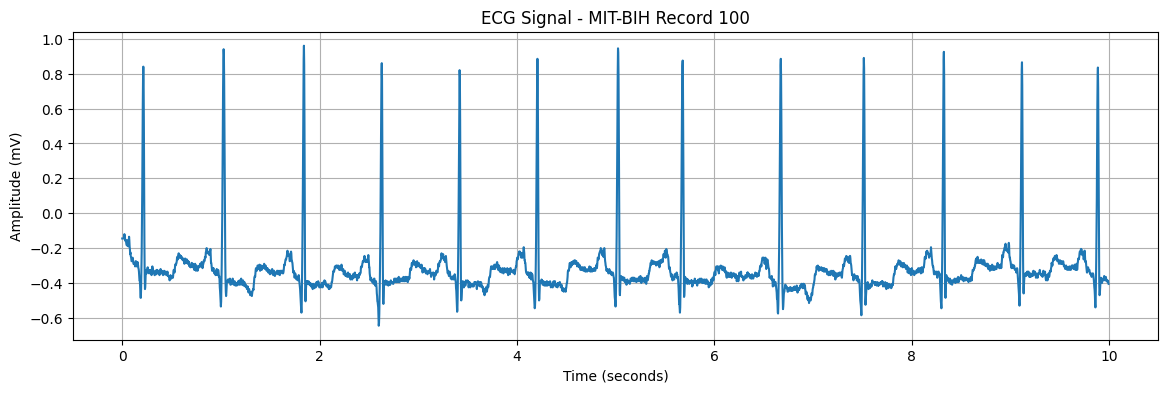

In [11]:
duration = 10

samples = int(duration * sampling_rate)

signal_segment = ecg_signal[:samples]

time = np.arange(samples) / sampling_rate

plt.figure(figsize=(14, 4))

plt.plot(time, signal_segment)

plt.title("ECG Signal - MIT-BIH Record 100")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (mV)")
plt.grid(True)

plt.show()

In [12]:
annotation = wfdb.rdann(
    "100",
    "atr",
    pn_dir="mitdb"
)

print("Total annotations:", len(annotation.sample))
print("First 20 annotation symbols:")
print(annotation.symbol[:20])

Total annotations: 2274
First 20 annotation symbols:
['+', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'A', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N']


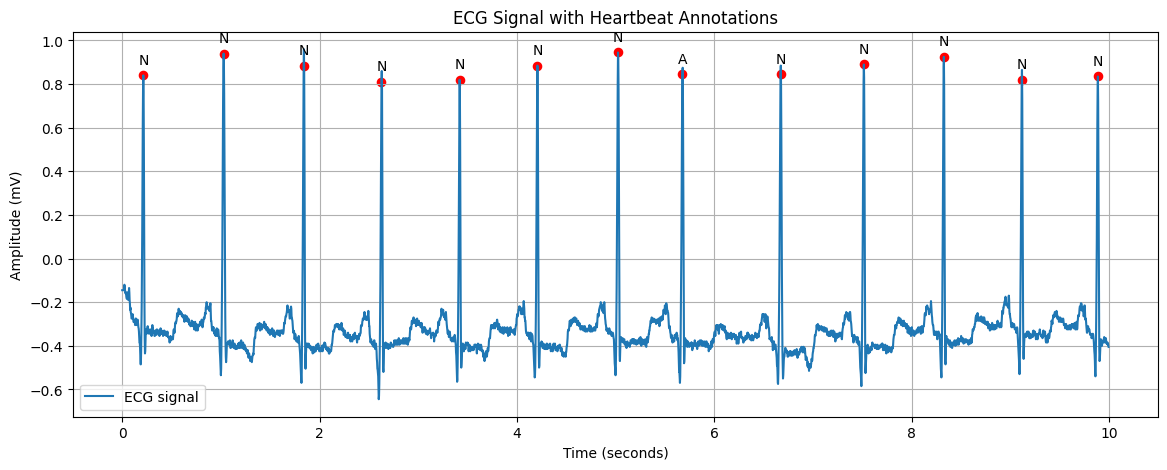

In [13]:
duration = 10
end_sample = int(duration * sampling_rate)

beat_symbols = {
    "N", "L", "R", "A", "a", "J", "S",
    "V", "E", "F", "e", "j", "/", "f", "Q"
}

beat_positions = [
    (sample, symbol)
    for sample, symbol in zip(
        annotation.sample,
        annotation.symbol
    )
    if sample < end_sample and symbol in beat_symbols
]

plt.figure(figsize=(14, 5))

plt.plot(
    time,
    signal_segment,
    label="ECG signal"
)

for sample, symbol in beat_positions:
    plt.scatter(
        sample / sampling_rate,
        ecg_signal[sample],
        color="red",
        s=35
    )

    plt.annotate(
        symbol,
        (sample / sampling_rate, ecg_signal[sample]),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center"
    )

plt.title("ECG Signal with Heartbeat Annotations")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (mV)")
plt.grid(True)
plt.legend()

plt.show()

In [14]:
from collections import Counter

beat_counts = Counter(
    symbol
    for symbol in annotation.symbol
    if symbol in beat_symbols
)

print("Heartbeat distribution:")
print(beat_counts)

Heartbeat distribution:
Counter({'N': 2239, 'A': 33, 'V': 1})


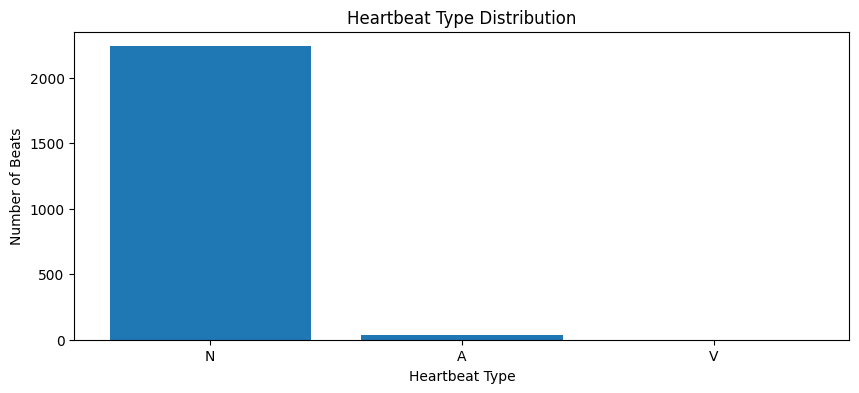

In [15]:
plt.figure(figsize=(10, 4))

plt.bar(
    list(beat_counts.keys()),
    list(beat_counts.values())
)

plt.title("Heartbeat Type Distribution")
plt.xlabel("Heartbeat Type")
plt.ylabel("Number of Beats")

plt.show()

In [16]:
from pathlib import Path

Path("data/raw").mkdir(parents=True, exist_ok=True)

np.save(
    "data/raw/ecg_record_100.npy",
    ecg_signal
)

annotation_df = pd.DataFrame({
    "sample": annotation.sample,
    "symbol": annotation.symbol
})

annotation_df.to_csv(
    "data/raw/annotations_100.csv",
    index=False
)

print("ECG signal and annotations saved!")

ECG signal and annotations saved!


In [17]:
ecg_signal = record.p_signal[:, 0]
sampling_rate = int(record.fs)

print("Number of samples:", len(ecg_signal))
print("Sampling rate:", sampling_rate)
print("First 10 samples:", ecg_signal[:10])

assert len(ecg_signal) > 0
assert sampling_rate == 360
assert np.isfinite(ecg_signal).all()

print("Signal verification passed!")

Number of samples: 650000
Sampling rate: 360
First 10 samples: [-0.145 -0.145 -0.145 -0.145 -0.145 -0.145 -0.145 -0.145 -0.12  -0.135]
Signal verification passed!


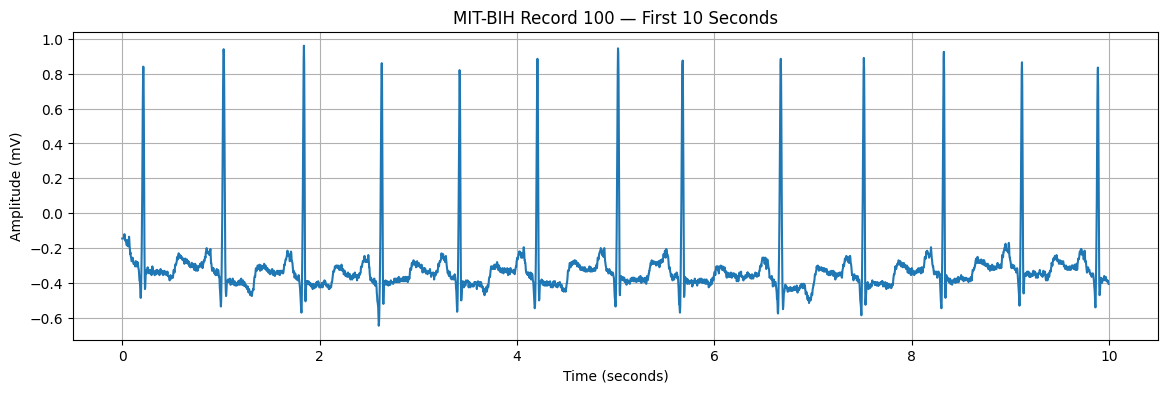

In [18]:
duration_seconds = 10
n_samples = duration_seconds * sampling_rate

segment = ecg_signal[:n_samples]
time_axis = np.arange(len(segment)) / sampling_rate

plt.figure(figsize=(14, 4))
plt.plot(time_axis, segment)
plt.title("MIT-BIH Record 100 — First 10 Seconds")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (mV)")
plt.grid(True)
plt.show()

In [20]:
beat_symbols = {
    "N", "L", "R", "A", "a", "J", "S",
    "V", "E", "F", "e", "j", "/", "f", "Q"
}

beat_df = pd.DataFrame({
    "sample": annotation.sample,
    "symbol": annotation.symbol
})

beat_df = beat_df[beat_df["symbol"].isin(beat_symbols)]

print(beat_df.head(10))
print("\nBeat counts:")
print(beat_df["symbol"].value_counts())

    sample symbol
1       77      N
2      370      N
3      662      N
4      946      N
5     1231      N
6     1515      N
7     1809      N
8     2044      A
9     2402      N
10    2706      N

Beat counts:
symbol
N    2239
A      33
V       1
Name: count, dtype: int64


In [21]:
from pathlib import Path

Path("data/raw").mkdir(parents=True, exist_ok=True)

np.save("data/raw/ecg_record_100.npy", ecg_signal)
beat_df.to_csv("data/raw/annotations_100.csv", index=False)

print("Saved ECG:", Path("data/raw/ecg_record_100.npy").exists())
print("Saved annotations:",
      Path("data/raw/annotations_100.csv").exists())

Saved ECG: True
Saved annotations: True


In [22]:
%pip install -q wfdb

In [23]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wfdb

print("WFDB version:", wfdb.__version__)
print("NumPy version:", np.__version__)
print("Imports successful!")

WFDB version: 4.3.1
NumPy version: 2.1.3
Imports successful!


In [24]:
record = wfdb.rdrecord("100", pn_dir="mitdb")

print("Record loaded successfully!")
print("Sampling rate:", record.fs, "Hz")
print("Signal shape:", record.p_signal.shape)
print("Channels:", record.sig_name)
print("Duration:", round(len(record.p_signal) / record.fs, 2), "seconds")

Record loaded successfully!
Sampling rate: 360 Hz
Signal shape: (650000, 2)
Channels: ['MLII', 'V5']
Duration: 1805.56 seconds


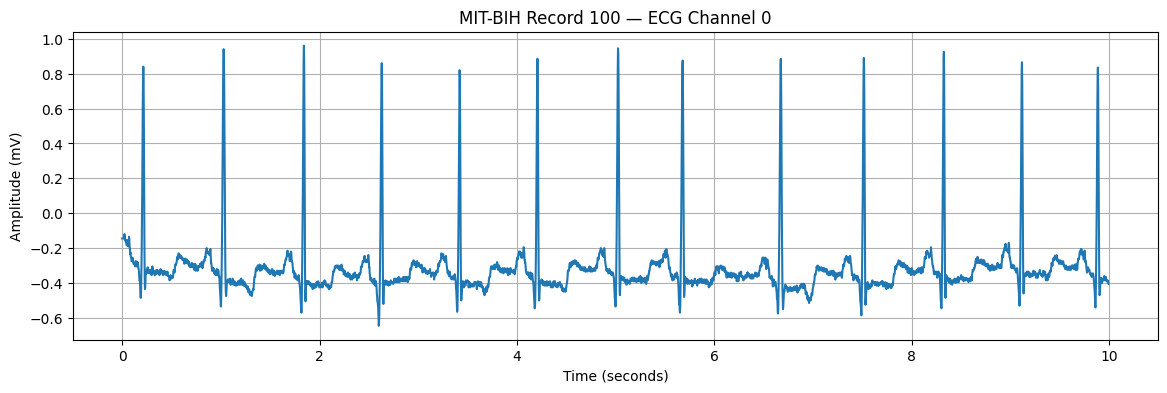

ECG signal length: 650000
First 10-second segment: [-0.145 -0.145 -0.145 -0.145 -0.145]


In [25]:
sampling_rate = int(record.fs)
ecg_signal = record.p_signal[:, 0]

seconds_to_plot = 10
num_samples = seconds_to_plot * sampling_rate

time_axis = np.arange(num_samples) / sampling_rate

plt.figure(figsize=(14, 4))
plt.plot(time_axis, ecg_signal[:num_samples])
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (mV)")
plt.title("MIT-BIH Record 100 — ECG Channel 0")
plt.grid(True)
plt.show()

print("ECG signal length:", len(ecg_signal))
print("First 10-second segment:", ecg_signal[:5])

In [26]:
annotation = wfdb.rdann("100", "atr", pn_dir="mitdb")

print("Annotations loaded successfully!")
print("Total annotation samples:", len(annotation.sample))
print("First 10 annotation symbols:", annotation.symbol[:10])
print("First 10 annotation positions:", annotation.sample[:10])

Annotations loaded successfully!
Total annotation samples: 2274
First 10 annotation symbols: ['+', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'A', 'N']
First 10 annotation positions: [  18   77  370  662  946 1231 1515 1809 2044 2402]


In [27]:
from collections import Counter

annotation_counts = Counter(annotation.symbol)

print("Annotation counts:")
for symbol, count in annotation_counts.most_common():
    print(repr(symbol), ":", count)

Annotation counts:
'N' : 2239
'A' : 33
'+' : 1
'V' : 1


In [28]:
beat_symbols = {
    "N", "L", "R", "A", "a", "J", "S", "V",
    "E", "F", "e", "j", "/", "f", "Q"
}

valid_indices = [
    i for i, symbol in enumerate(annotation.symbol)
    if symbol in beat_symbols
]

beat_samples = np.asarray(annotation.sample)[valid_indices]
beat_labels = np.asarray(annotation.symbol)[valid_indices]

print("Filtered beat count:", len(beat_samples))
print("Filtered labels:", Counter(beat_labels))

Filtered beat count: 2273
Filtered labels: Counter({np.str_('N'): 2239, np.str_('A'): 33, np.str_('V'): 1})


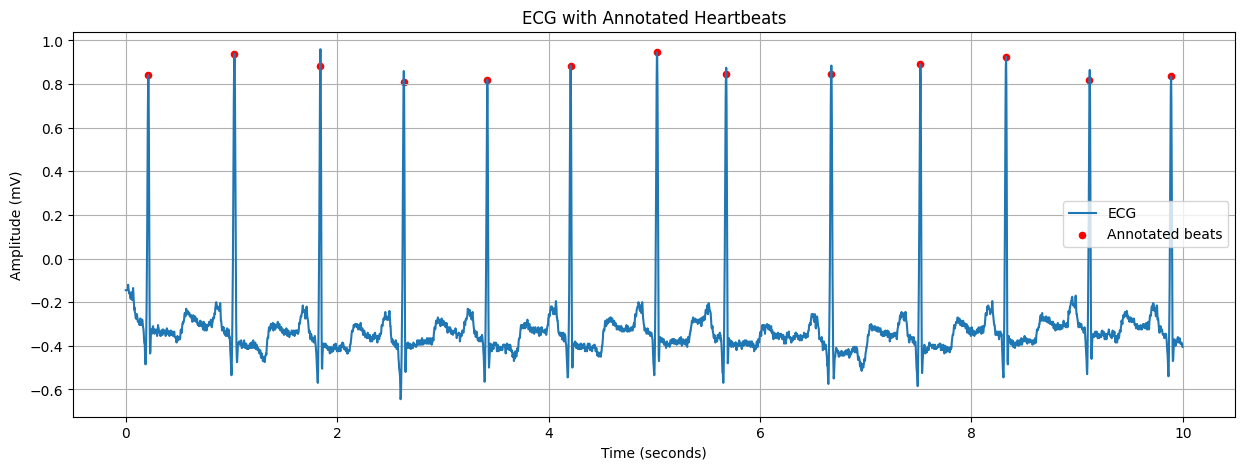

In [29]:
plot_seconds = 10
plot_samples = plot_seconds * sampling_rate

mask = beat_samples < plot_samples
plot_beat_samples = beat_samples[mask]
plot_beat_labels = beat_labels[mask]

plt.figure(figsize=(15, 5))
plt.plot(
    np.arange(plot_samples) / sampling_rate,
    ecg_signal[:plot_samples],
    label="ECG"
)

plt.scatter(
    plot_beat_samples / sampling_rate,
    ecg_signal[plot_beat_samples],
    color="red",
    s=20,
    label="Annotated beats"
)

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (mV)")
plt.title("ECG with Annotated Heartbeats")
plt.legend()
plt.grid(True)
plt.show()

In [30]:
os.makedirs("data/raw", exist_ok=True)

np.save("data/raw/ecg_record_100.npy", ecg_signal)

annotations_df = pd.DataFrame({
    "sample": beat_samples,
    "time_seconds": beat_samples / sampling_rate,
    "symbol": beat_labels
})

annotations_df.to_csv(
    "data/raw/annotations_100.csv",
    index=False
)

print("Saved files:")
print("1. data/raw/ecg_record_100.npy")
print("2. data/raw/annotations_100.csv")

print("ECG shape:", np.load("data/raw/ecg_record_100.npy").shape)
print("Annotation table shape:", pd.read_csv("data/raw/annotations_100.csv").shape)

Saved files:
1. data/raw/ecg_record_100.npy
2. data/raw/annotations_100.csv
ECG shape: (650000,)
Annotation table shape: (2273, 3)


In [31]:
%pip install -q scipy scikit-learn

In [32]:
from scipy.signal import butter, sosfiltfilt
from sklearn.model_selection import train_test_split

print("Preprocessing libraries ready!")

Preprocessing libraries ready!


In [33]:
# Ensure the Stage 2 variables exist before proceeding
assert "ecg_signal" in globals(), "Run Stage 2 first."
assert "beat_samples" in globals(), "Load annotations in Stage 2 first."
assert "beat_labels" in globals(), "Load annotations in Stage 2 first."

ecg_signal = np.asarray(ecg_signal, dtype=np.float64)

print("Signal samples:", len(ecg_signal))
print("Sampling rate:", sampling_rate)
print("Missing or infinite values:", np.sum(~np.isfinite(ecg_signal)))

Signal samples: 650000
Sampling rate: 360
Missing or infinite values: 0


In [34]:
# Interpolate invalid samples if present
valid = np.isfinite(ecg_signal)

if not np.all(valid):
    if valid.sum() < 2:
        raise ValueError("Not enough valid ECG samples to preprocess.")

    positions = np.arange(len(ecg_signal))
    ecg_signal[~valid] = np.interp(
        positions[~valid],
        positions[valid],
        ecg_signal[valid]
    )

# Bandpass filter: 0.5–40 Hz
low_cut = 0.5
high_cut = 40.0
nyquist = sampling_rate / 2

if high_cut >= nyquist:
    raise ValueError("High cutoff must be below the Nyquist frequency.")

sos = butter(
    4,
    [low_cut, high_cut],
    btype="bandpass",
    fs=sampling_rate,
    output="sos"
)

filtered_ecg = sosfiltfilt(sos, ecg_signal)

print("Filtering complete.")
print("Filtered signal shape:", filtered_ecg.shape)
print("All values finite:", np.isfinite(filtered_ecg).all())

Filtering complete.
Filtered signal shape: (650000,)
All values finite: True


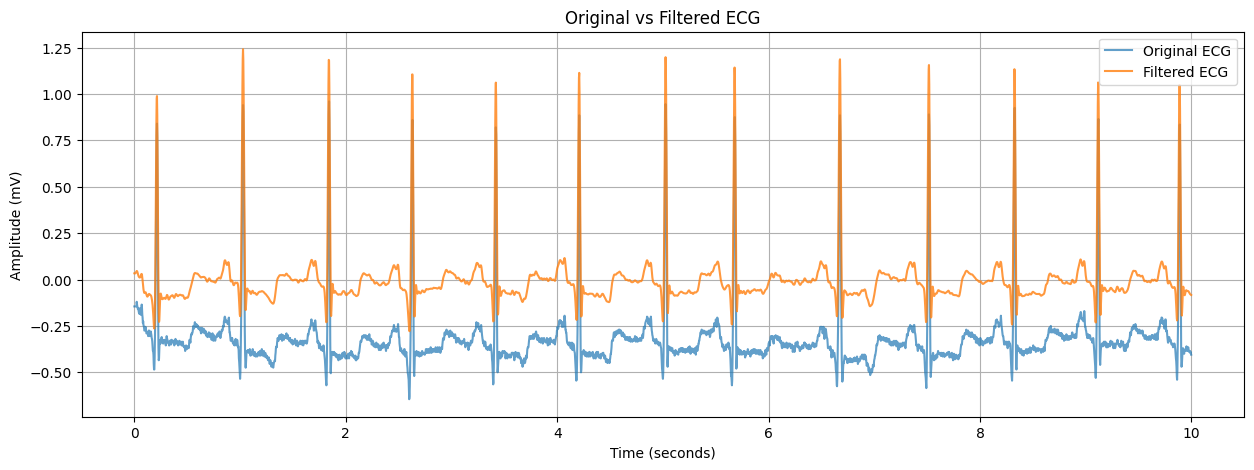

In [35]:
seconds = 10
n = seconds * sampling_rate
t = np.arange(n) / sampling_rate

plt.figure(figsize=(15, 5))
plt.plot(t, ecg_signal[:n], label="Original ECG", alpha=0.7)
plt.plot(t, filtered_ecg[:n], label="Filtered ECG", alpha=0.8)
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (mV)")
plt.title("Original vs Filtered ECG")
plt.legend()
plt.grid(True)
plt.show()

In [36]:
pre_seconds = 0.25
post_seconds = 0.40

pre_samples = int(pre_seconds * sampling_rate)
post_samples = int(post_seconds * sampling_rate)
segment_length = pre_samples + post_samples

segments = []
segment_labels = []
segment_centers = []

for sample, label in zip(beat_samples, beat_labels):
    start = int(sample) - pre_samples
    end = int(sample) + post_samples

    # Skip segments that extend beyond the signal
    if start < 0 or end > len(filtered_ecg):
        continue

    segment = filtered_ecg[start:end]

    # Keep only segments of the expected length
    if len(segment) != segment_length:
        continue

    segments.append(segment)
    segment_labels.append(label)
    segment_centers.append(int(sample))

X_segments = np.asarray(segments, dtype=np.float32)
y_symbols = np.asarray(segment_labels)
segment_centers = np.asarray(segment_centers)

print("Heartbeat segments shape:", X_segments.shape)
print("Heartbeat labels shape:", y_symbols.shape)
print("Segment length:", segment_length, "samples")
print("Labels:", Counter(y_symbols))

Heartbeat segments shape: (2271, 234)
Heartbeat labels shape: (2271,)
Segment length: 234 samples
Labels: Counter({np.str_('N'): 2237, np.str_('A'): 33, np.str_('V'): 1})


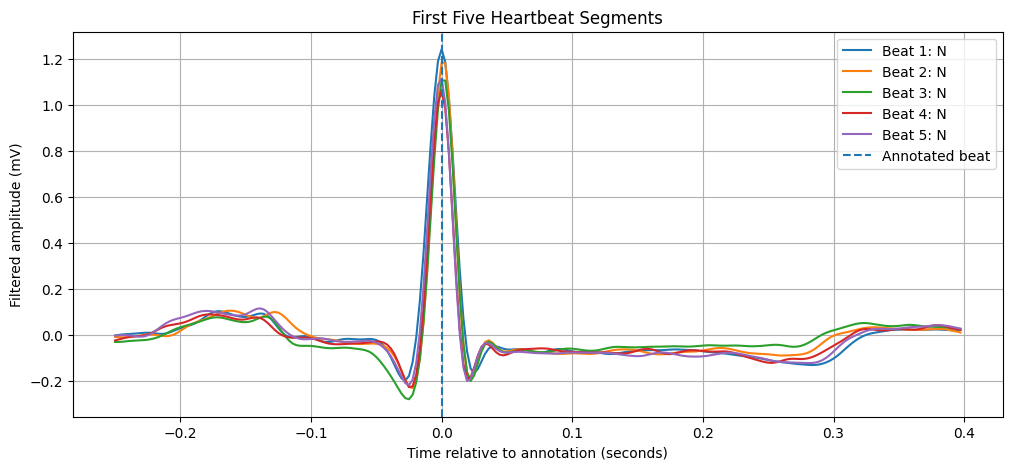

In [37]:
plt.figure(figsize=(12, 5))

for i in range(min(5, len(X_segments))):
    relative_time = (
        np.arange(segment_length) - pre_samples
    ) / sampling_rate

    plt.plot(
        relative_time,
        X_segments[i],
        label=f"Beat {i + 1}: {y_symbols[i]}"
    )

plt.axvline(0, linestyle="--", label="Annotated beat")
plt.xlabel("Time relative to annotation (seconds)")
plt.ylabel("Filtered amplitude (mV)")
plt.title("First Five Heartbeat Segments")
plt.legend()
plt.grid(True)
plt.show()

In [38]:
y_binary = np.where(y_symbols == "N", 0, 1).astype(np.int64)

print("0 = Normal (N)")
print("1 = Other retained beat types")
print("Class counts:", Counter(y_binary))

0 = Normal (N)
1 = Other retained beat types
Class counts: Counter({np.int64(0): 2237, np.int64(1): 34})


In [39]:
os.makedirs("data/processed", exist_ok=True)

np.savez_compressed(
    "data/processed/heartbeat_segments.npz",
    X=X_segments,
    y=y_binary,
    symbols=y_symbols,
    centers=segment_centers,
    sampling_rate=sampling_rate
)

print("Saved: data/processed/heartbeat_segments.npz")
print("X shape:", X_segments.shape)
print("y shape:", y_binary.shape)

Saved: data/processed/heartbeat_segments.npz
X shape: (2271, 234)
y shape: (2271,)


In [40]:
saved = np.load("data/processed/heartbeat_segments.npz")

print("Keys:", saved.files)
print("Saved X shape:", saved["X"].shape)
print("Saved y shape:", saved["y"].shape)
print("Saved symbols shape:", saved["symbols"].shape)

Keys: ['X', 'y', 'symbols', 'centers', 'sampling_rate']
Saved X shape: (2271, 234)
Saved y shape: (2271,)
Saved symbols shape: (2271,)


In [41]:
X_train, X_test, y_train, y_test = train_test_split(
    X_segments,
    y_binary,
    test_size=0.20,
    random_state=42,
    stratify=y_binary
)

print("Training segments:", X_train.shape)
print("Test segments:", X_test.shape)
print("Training class counts:", Counter(y_train))
print("Test class counts:", Counter(y_test))

Training segments: (1816, 234)
Test segments: (455, 234)
Training class counts: Counter({np.int64(0): 1789, np.int64(1): 27})
Test class counts: Counter({np.int64(0): 448, np.int64(1): 7})


QFF 2026 ECG VQC PROJECT

STEP 2: Loading ECG record and annotations...
Record loaded successfully!
Channels: ['MLII', 'V5']
Sampling rate: 360 Hz
ECG shape: (650000,)
Duration: 1805.56 seconds

Annotation counts:
Counter({np.str_('N'): 2239, np.str_('A'): 33, np.str_('V'): 1})


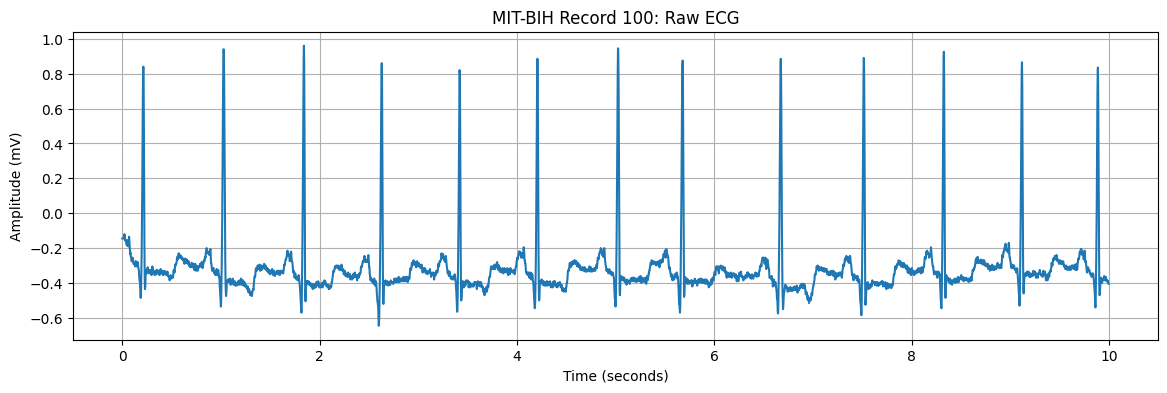

Raw ECG and annotation files saved.

Invalid values remaining: 0
Filtered ECG shape: (650000,)
Filtered values finite: True


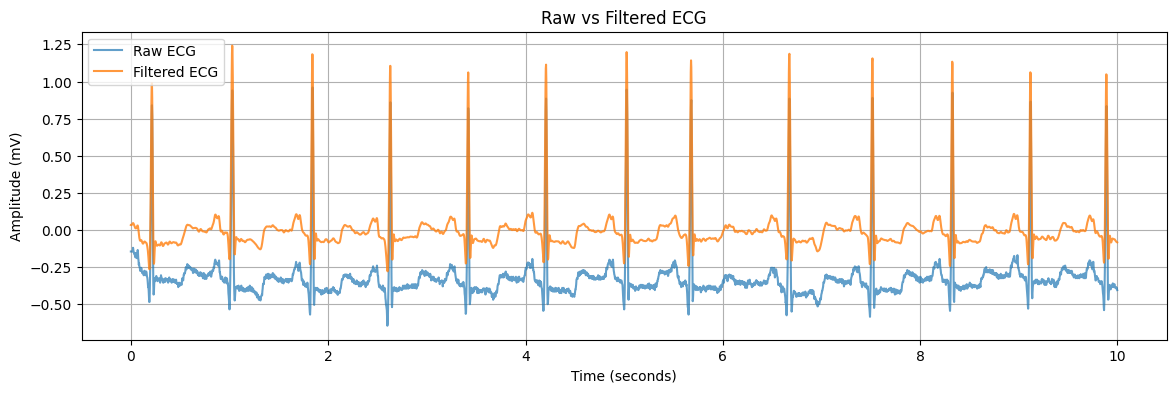


Heartbeat segmentation complete!
Segments shape: (2271, 234)
Expected samples per segment: 234
Beat class counts: Counter({np.str_('N'): 2237, np.str_('A'): 33, np.str_('V'): 1})


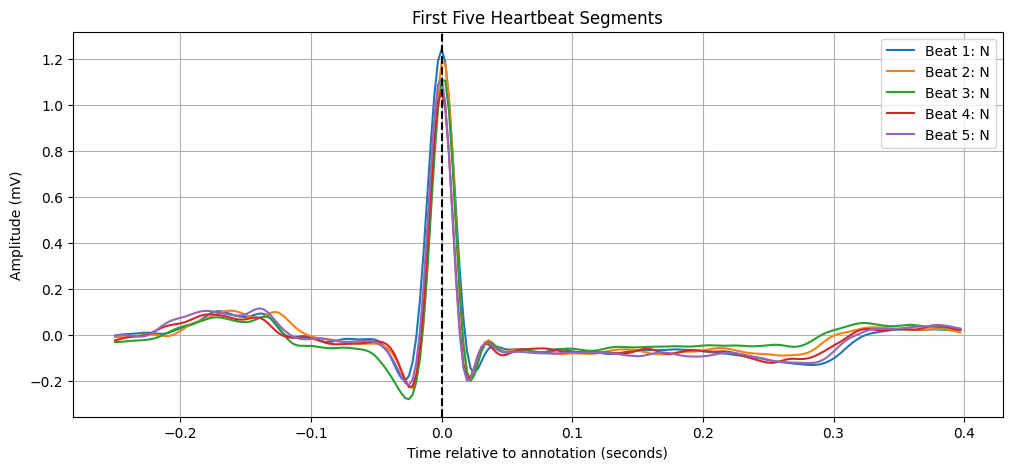


Binary class counts:
Counter({np.int64(0): 2237, np.int64(1): 34})

Feature extraction complete!
Feature matrix shape: (2271, 4)
Feature names: ['mean', 'std', 'rms', 'peak_to_peak']
First five feature rows:
 [[ 0.00630441  0.20532452  0.20542129  1.43843673]
 [ 0.00564647  0.18507923  0.18516534  1.41416219]
 [ 0.002574    0.17593898  0.1759578   1.38389128]
 [-0.00447153  0.16617321  0.16623336  1.28681013]
 [-0.00189521  0.17846967  0.17847973  1.33108301]]

Training data shape: (1816, 4)
Testing data shape: (455, 4)
Training classes: Counter({np.int64(0): 1789, np.int64(1): 27})
Testing classes: Counter({np.int64(0): 448, np.int64(1): 7})

Quantum-ready data created!
Training angles shape: (1816, 4)
Testing angles shape: (455, 4)
Training angle range: 0.0 to 3.141592653589793
First encoded sample: [2.02389687 0.35794026 0.35743947 0.60770528]

FINAL VERIFICATION
Raw ECG exists: True
Raw annotations exist: True
Heartbeat segments exist: True
Quantum-ready data exists: True
Feature 

In [42]:

# ============================================================
# QFF 2026 ECG VQC PROJECT
# STAGE 2: ECG DATA LOADING
# STAGE 3: PREPROCESSING AND HEARTBEAT SEGMENTATION
# STAGE 4: FEATURE EXTRACTION AND QUANTUM-READY DATA
# ============================================================

%pip install -q wfdb scipy scikit-learn joblib

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wfdb
import joblib

from collections import Counter
from scipy.signal import butter, sosfiltfilt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

# ------------------------------------------------------------
# STEP 1: CREATE PROJECT DIRECTORIES
# ------------------------------------------------------------

os.makedirs("data/raw", exist_ok=True)
os.makedirs("data/processed", exist_ok=True)

print("=" * 60)
print("QFF 2026 ECG VQC PROJECT")
print("=" * 60)

# ------------------------------------------------------------
# STEP 2: LOAD MIT-BIH ECG RECORD 100 AND ANNOTATIONS
# ------------------------------------------------------------

print("\nSTEP 2: Loading ECG record and annotations...")

record = wfdb.rdrecord("100", pn_dir="mitdb")
annotation = wfdb.rdann("100", "atr", pn_dir="mitdb")

sampling_rate = int(record.fs)
ecg_signal = np.asarray(record.p_signal[:, 0], dtype=np.float64)

print("Record loaded successfully!")
print("Channels:", record.sig_name)
print("Sampling rate:", sampling_rate, "Hz")
print("ECG shape:", ecg_signal.shape)
print("Duration:", round(len(ecg_signal) / sampling_rate, 2), "seconds")

# ------------------------------------------------------------
# STEP 3: FILTER HEARTBEAT ANNOTATIONS
# ------------------------------------------------------------

beat_symbols = {
    "N", "L", "R", "A", "a", "J", "S", "V",
    "E", "F", "e", "j", "/", "f", "Q"
}

valid_indices = [
    i for i, symbol in enumerate(annotation.symbol)
    if symbol in beat_symbols
]

beat_samples = np.asarray(annotation.sample)[valid_indices]
beat_labels = np.asarray(annotation.symbol)[valid_indices]

print("\nAnnotation counts:")
print(Counter(beat_labels))

# ------------------------------------------------------------
# STEP 4: VISUALIZE RAW ECG
# ------------------------------------------------------------

plot_samples = min(10 * sampling_rate, len(ecg_signal))
time_axis = np.arange(plot_samples) / sampling_rate

plt.figure(figsize=(14, 4))
plt.plot(time_axis, ecg_signal[:plot_samples])
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (mV)")
plt.title("MIT-BIH Record 100: Raw ECG")
plt.grid(True)
plt.show()

# ------------------------------------------------------------
# STEP 5: SAVE RAW DATA
# ------------------------------------------------------------

np.save("data/raw/ecg_record_100.npy", ecg_signal)

raw_annotations = pd.DataFrame({
    "sample": beat_samples,
    "time_seconds": beat_samples / sampling_rate,
    "symbol": beat_labels
})

raw_annotations.to_csv(
    "data/raw/annotations_100.csv",
    index=False
)

print("Raw ECG and annotation files saved.")

# ------------------------------------------------------------
# STEP 6: HANDLE INVALID VALUES
# ------------------------------------------------------------

valid = np.isfinite(ecg_signal)

if not valid.all():
    if valid.sum() < 2:
        raise ValueError("Not enough valid ECG samples.")

    positions = np.arange(len(ecg_signal))

    ecg_signal[~valid] = np.interp(
        positions[~valid],
        positions[valid],
        ecg_signal[valid]
    )

print("\nInvalid values remaining:", np.sum(~np.isfinite(ecg_signal)))

# ------------------------------------------------------------
# STEP 7: FILTER ECG SIGNAL
# ------------------------------------------------------------

sos = butter(
    4,
    [0.5, 40.0],
    btype="bandpass",
    fs=sampling_rate,
    output="sos"
)

filtered_ecg = sosfiltfilt(sos, ecg_signal)

print("Filtered ECG shape:", filtered_ecg.shape)
print("Filtered values finite:", np.isfinite(filtered_ecg).all())

# Plot raw and filtered ECG for comparison
plt.figure(figsize=(14, 4))
plt.plot(time_axis, ecg_signal[:plot_samples],
         label="Raw ECG", alpha=0.7)
plt.plot(time_axis, filtered_ecg[:plot_samples],
         label="Filtered ECG", alpha=0.8)
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (mV)")
plt.title("Raw vs Filtered ECG")
plt.legend()
plt.grid(True)
plt.show()

# ------------------------------------------------------------
# STEP 8: SEGMENT INDIVIDUAL HEARTBEATS
# ------------------------------------------------------------

pre_samples = int(0.25 * sampling_rate)
post_samples = int(0.40 * sampling_rate)
expected_length = pre_samples + post_samples

segments = []
segment_labels = []
segment_centers = []

for sample, label in zip(beat_samples, beat_labels):

    start = int(sample) - pre_samples
    end = int(sample) + post_samples

    # Skip beats too close to signal boundaries
    if start < 0 or end > len(filtered_ecg):
        continue

    segment = filtered_ecg[start:end]

    if len(segment) == expected_length:
        segments.append(segment)
        segment_labels.append(label)
        segment_centers.append(int(sample))

X_segments = np.asarray(segments, dtype=np.float32)
y_symbols = np.asarray(segment_labels)
segment_centers = np.asarray(segment_centers)

print("\nHeartbeat segmentation complete!")
print("Segments shape:", X_segments.shape)
print("Expected samples per segment:", expected_length)
print("Beat class counts:", Counter(y_symbols))

assert X_segments.ndim == 2
assert X_segments.shape[1] == expected_length
assert len(X_segments) == len(y_symbols)
assert len(X_segments) > 0
assert np.isfinite(X_segments).all()

# ------------------------------------------------------------
# STEP 9: VISUALIZE HEARTBEAT SEGMENTS
# ------------------------------------------------------------

relative_time = (
    np.arange(expected_length) - pre_samples
) / sampling_rate

plt.figure(figsize=(12, 5))

for i in range(min(5, len(X_segments))):
    plt.plot(
        relative_time,
        X_segments[i],
        label=f"Beat {i + 1}: {y_symbols[i]}"
    )

plt.axvline(0, linestyle="--", color="black")
plt.xlabel("Time relative to annotation (seconds)")
plt.ylabel("Amplitude (mV)")
plt.title("First Five Heartbeat Segments")
plt.legend()
plt.grid(True)
plt.show()

# ------------------------------------------------------------
# STEP 10: CREATE BINARY LABELS
# 0 = NORMAL BEAT (N)
# 1 = OTHER RETAINED BEAT TYPES
# ------------------------------------------------------------

y_binary = (y_symbols != "N").astype(np.int64)

print("\nBinary class counts:")
print(Counter(y_binary))

if len(np.unique(y_binary)) != 2:
    raise ValueError(
        "Both classes are required. Inspect annotation counts."
    )

# Save segmented data
np.savez_compressed(
    "data/processed/heartbeat_segments.npz",
    X=X_segments,
    y=y_binary,
    symbols=y_symbols,
    centers=segment_centers,
    sampling_rate=sampling_rate
)

# ------------------------------------------------------------
# STEP 11: EXTRACT FOUR FEATURES PER HEARTBEAT
# ------------------------------------------------------------

def extract_features(segment):
    segment = np.asarray(segment, dtype=np.float64)

    return [
        np.mean(segment),
        np.std(segment),
        np.sqrt(np.mean(segment ** 2)),
        np.max(segment) - np.min(segment)
    ]

feature_names = [
    "mean",
    "std",
    "rms",
    "peak_to_peak"
]

X_features = np.asarray(
    [extract_features(segment) for segment in X_segments],
    dtype=np.float64
)

print("\nFeature extraction complete!")
print("Feature matrix shape:", X_features.shape)
print("Feature names:", feature_names)
print("First five feature rows:\n", X_features[:5])

assert X_features.shape == (len(X_segments), 4)
assert np.isfinite(X_features).all()

# ------------------------------------------------------------
# STEP 12: SPLIT DATA INTO TRAINING AND TEST SETS
# ------------------------------------------------------------

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_features,
    y_binary,
    test_size=0.20,
    random_state=42,
    stratify=y_binary
)

print("\nTraining data shape:", X_train_raw.shape)
print("Testing data shape:", X_test_raw.shape)
print("Training classes:", Counter(y_train))
print("Testing classes:", Counter(y_test))

# ------------------------------------------------------------
# STEP 13: SCALE FEATURES TO QUANTUM ROTATION ANGLES
# ------------------------------------------------------------

scaler = MinMaxScaler(feature_range=(0, np.pi))

# Fit on training data only
X_train_angles = scaler.fit_transform(X_train_raw)
X_test_angles = scaler.transform(X_test_raw)

print("\nQuantum-ready data created!")
print("Training angles shape:", X_train_angles.shape)
print("Testing angles shape:", X_test_angles.shape)
print("Training angle range:",
      X_train_angles.min(), "to", X_train_angles.max())
print("First encoded sample:", X_train_angles[0])

assert X_train_angles.shape[1] == 4
assert X_test_angles.shape[1] == 4
assert np.isfinite(X_train_angles).all()
assert np.isfinite(X_test_angles).all()

# ------------------------------------------------------------
# STEP 14: SAVE STAGE 4 OUTPUTS
# ------------------------------------------------------------

np.savez_compressed(
    "data/processed/quantum_ready_data.npz",
    X_train=X_train_angles,
    X_test=X_test_angles,
    y_train=y_train,
    y_test=y_test,
    feature_names=np.asarray(feature_names)
)

joblib.dump(
    scaler,
    "data/processed/feature_scaler.joblib"
)

# ------------------------------------------------------------
# STEP 15: VERIFY SAVED FILES
# ------------------------------------------------------------

saved = np.load("data/processed/heartbeat_segments.npz")
quantum_data = np.load("data/processed/quantum_ready_data.npz")

print("\n" + "=" * 60)
print("FINAL VERIFICATION")
print("=" * 60)

print("Raw ECG exists:",
      os.path.exists("data/raw/ecg_record_100.npy"))
print("Raw annotations exist:",
      os.path.exists("data/raw/annotations_100.csv"))
print("Heartbeat segments exist:",
      os.path.exists("data/processed/heartbeat_segments.npz"))
print("Quantum-ready data exists:",
      os.path.exists("data/processed/quantum_ready_data.npz"))
print("Feature scaler exists:",
      os.path.exists("data/processed/feature_scaler.joblib"))

print("Reloaded heartbeat shape:", saved["X"].shape)
print("Reloaded quantum training shape:",
      quantum_data["X_train"].shape)
print("Reloaded quantum testing shape:",
      quantum_data["X_test"].shape)

print("\nSUCCESS: Stages 2, 3, and 4 completed.")
print("Next: Stage 5 — Variational Quantum Circuit (VQC).")


Training data: (1816, 4)
Testing data: (455, 4)
Training classes: (array([0, 1]), array([1789,   27]))
Testing classes: (array([0, 1]), array([448,   7]))
Number of qubits: 4
Trainable parameters: 16
Test expectation value: -0.33463170743672666
Samples used for VQC training: 107
Training subset classes: (array([0, 1]), array([80, 27]))
Return from COBYLA because the objective function has been evaluated MAXFUN times.
Number of function values = 60   Least value of F = 0.5499714406882753
The corresponding X is:
[ 2.96482269  1.56552919  1.32407683  0.29912635  0.04392405 -0.24711427
  2.01771037  0.0780316  -0.01024447  0.23593289  0.4459349  -0.31331672
  2.79704655 -0.62981305  1.787616   -0.15850783]


Training finished.
Optimizer success: False
Final loss: 0.5499714406882753
Optimizer message: Return from COBYLA because the objective function has been evaluated MAXFUN times.

VQC TEST RESULTS
Accuracy: 0.9846153846153847
Precision: 0.0
Recall: 0.0
F1-score: 0.0

Classification repor

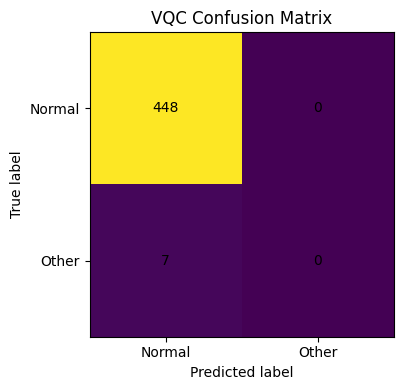


Saved model weights: models/vqc_weights.npy
Saved predictions: results/vqc_test_predictions.csv
Saved metrics: results/vqc_metrics.csv

STAGE 5 COMPLETE


In [43]:

# ============================================================
# QFF 2026 ECG VQC PROJECT — STAGE 5
# Variational Quantum Classifier using Qiskit
# 4 features -> 4 qubits -> binary classification
# ============================================================

%pip install -q qiskit scipy scikit-learn

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.optimize import minimize
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector, SparsePauliOp

# ------------------------------------------------------------
# STEP 1: LOAD STAGE 4 DATA
# ------------------------------------------------------------

DATA_PATH = "data/processed/quantum_ready_data.npz"

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        "Stage 4 data not found. Run the previous pipeline first."
    )

data = np.load(DATA_PATH)

X_train = np.asarray(data["X_train"], dtype=float)
X_test = np.asarray(data["X_test"], dtype=float)
y_train = np.asarray(data["y_train"], dtype=int)
y_test = np.asarray(data["y_test"], dtype=int)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("Training classes:", np.unique(y_train, return_counts=True))
print("Testing classes:", np.unique(y_test, return_counts=True))

assert X_train.ndim == 2 and X_train.shape[1] == 4
assert X_test.ndim == 2 and X_test.shape[1] == 4
assert set(np.unique(y_train)) == {0, 1}

# ------------------------------------------------------------
# STEP 2: DEFINE THE QUANTUM CIRCUIT
# ------------------------------------------------------------

N_QUBITS = 4
N_LAYERS = 2

def build_vqc_circuit(features, weights):
    """
    Encode four classical features with RY rotations.
    Apply trainable RX and RZ rotations and entangling CX gates.
    """
    qc = QuantumCircuit(N_QUBITS)

    # Feature/angle encoding
    for q in range(N_QUBITS):
        qc.ry(float(features[q]), q)

    # Trainable variational layers
    k = 0

    for layer in range(N_LAYERS):
        for q in range(N_QUBITS):
            qc.rx(float(weights[k]), q)
            k += 1
            qc.rz(float(weights[k]), q)
            k += 1

        # Entangle neighboring qubits
        for q in range(N_QUBITS - 1):
            qc.cx(q, q + 1)

        # Ring connection
        qc.cx(N_QUBITS - 1, 0)

    return qc


N_WEIGHTS = N_LAYERS * N_QUBITS * 2

print("Number of qubits:", N_QUBITS)
print("Trainable parameters:", N_WEIGHTS)

# ------------------------------------------------------------
# STEP 3: CALCULATE EXPECTATION VALUE OF Z ON QUBIT 0
# ------------------------------------------------------------

Z_OBSERVABLE = SparsePauliOp.from_list([
    ("IIIZ", 1.0)
])

def quantum_expectation(features, weights):
    circuit = build_vqc_circuit(features, weights)
    state = Statevector.from_instruction(circuit)

    # Qiskit Pauli strings label qubit 0 at the rightmost position.
    value = state.expectation_value(Z_OBSERVABLE)

    return float(np.real(value))


# Test one circuit before training
initial_weights = np.random.default_rng(42).uniform(
    -0.1, 0.1, size=N_WEIGHTS
)

test_value = quantum_expectation(X_train[0], initial_weights)

print("Test expectation value:", test_value)
assert -1.000001 <= test_value <= 1.000001

# ------------------------------------------------------------
# STEP 4: DEFINE THE CLASSIFICATION LOSS
# ------------------------------------------------------------

# Map expectation in [-1, 1] to probability in [0, 1].
# Class 1 is predicted when expectation < 0.

def predict_probability(features, weights):
    expectations = np.array([
        quantum_expectation(row, weights)
        for row in features
    ])

    probabilities = (1.0 - expectations) / 2.0
    return np.clip(probabilities, 1e-7, 1 - 1e-7)


def binary_cross_entropy(weights, X, y):
    probabilities = predict_probability(X, weights)

    loss = -np.mean(
        y * np.log(probabilities)
        + (1 - y) * np.log(1 - probabilities)
    )

    return float(loss)


# ------------------------------------------------------------
# STEP 5: TRAIN THE VQC
# ------------------------------------------------------------

# Full training data may be slow for a first simulator run.
# Use a stratified subset for debugging; later increase it.
rng = np.random.default_rng(42)
MAX_TRAIN_SAMPLES = min(160, len(X_train))

chosen = []

for label in [0, 1]:
    class_indices = np.where(y_train == label)[0]
    count = min(
        len(class_indices),
        MAX_TRAIN_SAMPLES // 2
    )
    chosen.extend(
        rng.choice(class_indices, size=count, replace=False).tolist()
    )

chosen = np.asarray(chosen)
rng.shuffle(chosen)

X_fit = X_train[chosen]
y_fit = y_train[chosen]

print("Samples used for VQC training:", len(X_fit))
print("Training subset classes:", np.unique(y_fit, return_counts=True))

initial_weights = rng.uniform(
    -0.1, 0.1, size=N_WEIGHTS
)

result = minimize(
    fun=binary_cross_entropy,
    x0=initial_weights,
    args=(X_fit, y_fit),
    method="COBYLA",
    options={
        "maxiter": 60,
        "rhobeg": 0.2,
        "disp": True
    }
)

trained_weights = result.x

print("\nTraining finished.")
print("Optimizer success:", result.success)
print("Final loss:", result.fun)
print("Optimizer message:", result.message)

# ------------------------------------------------------------
# STEP 6: PREDICT TEST LABELS
# ------------------------------------------------------------

test_probabilities = predict_probability(
    X_test, trained_weights
)

y_pred = (test_probabilities >= 0.5).astype(int)

# ------------------------------------------------------------
# STEP 7: EVALUATE THE CLASSIFIER
# ------------------------------------------------------------

print("\nVQC TEST RESULTS")
print("=" * 50)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(
    y_test, y_pred, zero_division=0
))
print("Recall:", recall_score(
    y_test, y_pred, zero_division=0
))
print("F1-score:", f1_score(
    y_test, y_pred, zero_division=0
))

print("\nClassification report:")
print(classification_report(
    y_test, y_pred, zero_division=0
))

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

plt.figure(figsize=(5, 4))
plt.imshow(cm)
plt.title("VQC Confusion Matrix")
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.xticks([0, 1], ["Normal", "Other"])
plt.yticks([0, 1], ["Normal", "Other"])

for i in range(2):
    for j in range(2):
        plt.text(j, i, str(cm[i, j]), ha="center", va="center")

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# STEP 8: SAVE THE MODEL PARAMETERS AND RESULTS
# ------------------------------------------------------------

os.makedirs("results", exist_ok=True)
os.makedirs("models", exist_ok=True)

np.save(
    "models/vqc_weights.npy",
    trained_weights
)

results_df = pd.DataFrame({
    "y_true": y_test,
    "y_pred": y_pred,
    "probability_class_1": test_probabilities
})

results_df.to_csv(
    "results/vqc_test_predictions.csv",
    index=False
)

metrics = {
    "accuracy": accuracy_score(y_test, y_pred),
    "precision": precision_score(y_test, y_pred, zero_division=0),
    "recall": recall_score(y_test, y_pred, zero_division=0),
    "f1": f1_score(y_test, y_pred, zero_division=0),
    "optimizer_loss": result.fun,
    "optimizer_iterations": result.nfev
}

pd.DataFrame([metrics]).to_csv(
    "results/vqc_metrics.csv",
    index=False
)

print("\nSaved model weights: models/vqc_weights.npy")
print("Saved predictions: results/vqc_test_predictions.csv")
print("Saved metrics: results/vqc_metrics.csv")
print("\nSTAGE 5 COMPLETE")


Training shape: (1816, 4)
Testing shape: (455, 4)
Training labels: (array([0, 1]), array([1789,   27]))
Testing labels: (array([0, 1]), array([448,   7]))

Logistic Regression training complete.

CLASSICAL BASELINE RESULTS
Accuracy: 0.7187
Precision: 0.0236
Recall: 0.4286
F1-score: 0.0448

Classification report:
              precision    recall  f1-score   support

           0       0.99      0.72      0.84       448
           1       0.02      0.43      0.04         7

    accuracy                           0.72       455
   macro avg       0.51      0.58      0.44       455
weighted avg       0.97      0.72      0.82       455



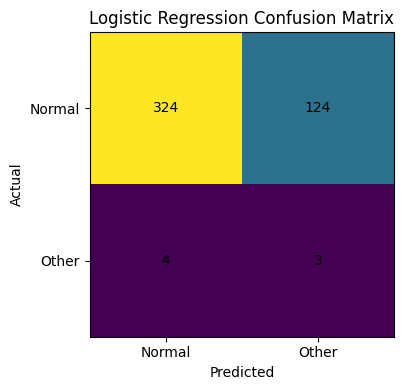


VQC RESULTS
Accuracy: 0.9846
Precision: 0.0000
Recall: 0.0000
F1-score: 0.0000

MODEL COMPARISON
              Model  Accuracy  Precision   Recall  F1-score
Logistic Regression  0.718681   0.023622 0.428571  0.044776
                VQC  0.984615   0.000000 0.000000  0.000000

Saved: results/model_comparison.csv


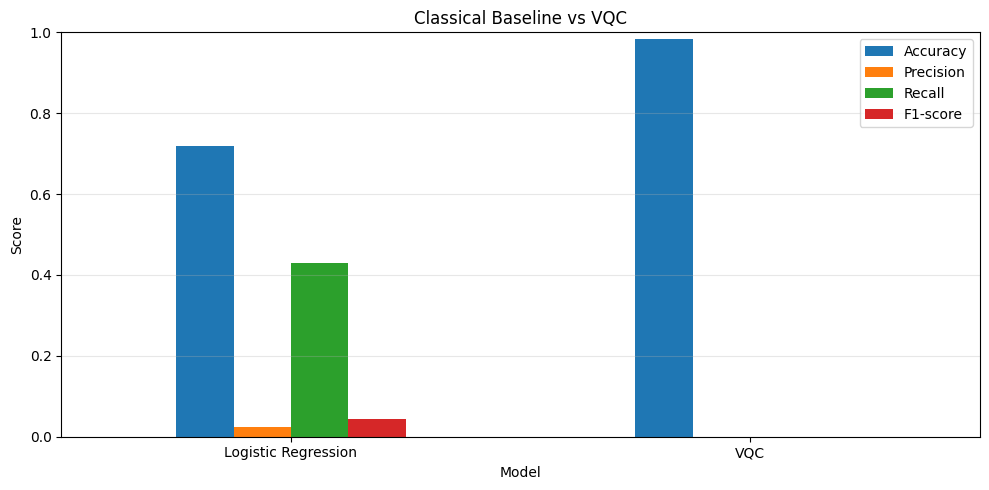


STAGE 6 COMPLETE


In [44]:

# ============================================================
# QFF 2026 ECG VQC PROJECT — STAGE 6
# Classical Baseline vs Variational Quantum Classifier
# ============================================================

%pip install -q scikit-learn pandas matplotlib

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# ------------------------------------------------------------
# STEP 1: LOAD THE SAME STAGE 4 TRAIN/TEST SPLIT
# ------------------------------------------------------------

data_path = "data/processed/quantum_ready_data.npz"

if not os.path.exists(data_path):
    raise FileNotFoundError(
        "Stage 4 data is missing. Run the Stage 2-4 pipeline first."
    )

data = np.load(data_path)

X_train = data["X_train"]
X_test = data["X_test"]
y_train = data["y_train"]
y_test = data["y_test"]

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)
print("Training labels:", np.unique(y_train, return_counts=True))
print("Testing labels:", np.unique(y_test, return_counts=True))

# ------------------------------------------------------------
# STEP 2: TRAIN CLASSICAL LOGISTIC REGRESSION
# ------------------------------------------------------------

classical_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

classical_model.fit(X_train, y_train)

classical_pred = classical_model.predict(X_test)

# Probability of class 1
classical_prob = classical_model.predict_proba(X_test)[:, 1]

print("\nLogistic Regression training complete.")

# ------------------------------------------------------------
# STEP 3: EVALUATE CLASSICAL MODEL
# ------------------------------------------------------------

def calculate_metrics(y_true, y_pred, model_name):
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_true, y_pred, zero_division=0
        )
    }

classical_metrics = calculate_metrics(
    y_test, classical_pred, "Logistic Regression"
)

print("\nCLASSICAL BASELINE RESULTS")
print("=" * 45)

for metric, value in classical_metrics.items():
    if metric != "Model":
        print(f"{metric}: {value:.4f}")

print("\nClassification report:")
print(classification_report(
    y_test,
    classical_pred,
    zero_division=0
))

# ------------------------------------------------------------
# STEP 4: PLOT CLASSICAL CONFUSION MATRIX
# ------------------------------------------------------------

cm = confusion_matrix(y_test, classical_pred, labels=[0, 1])

plt.figure(figsize=(5, 4))
plt.imshow(cm)
plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.xticks([0, 1], ["Normal", "Other"])
plt.yticks([0, 1], ["Normal", "Other"])

for i in range(2):
    for j in range(2):
        plt.text(j, i, str(cm[i, j]),
                 ha="center", va="center")

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# STEP 5: CHECK WHETHER TRAINED VQC WEIGHTS EXIST
# ------------------------------------------------------------

vqc_weights_path = "models/vqc_weights.npy"

results = [classical_metrics]

if (
    os.path.exists(vqc_weights_path)
    and "predict_probability" in globals()
):
    vqc_weights = np.load(vqc_weights_path)

    vqc_prob = predict_probability(X_test, vqc_weights)
    vqc_pred = (vqc_prob >= 0.5).astype(int)

    vqc_metrics = calculate_metrics(
        y_test, vqc_pred, "VQC"
    )

    results.append(vqc_metrics)

    print("\nVQC RESULTS")
    print("=" * 45)
    for metric, value in vqc_metrics.items():
        if metric != "Model":
            print(f"{metric}: {value:.4f}")

else:
    print(
        "\nVQC weights or prediction function not available. "
        "Run Stage 5 training again, then rerun this cell."
    )

# ------------------------------------------------------------
# STEP 6: COMPARE MODELS
# ------------------------------------------------------------

comparison = pd.DataFrame(results)

print("\nMODEL COMPARISON")
print("=" * 65)
print(comparison.to_string(index=False))

os.makedirs("results", exist_ok=True)

comparison.to_csv(
    "results/model_comparison.csv",
    index=False
)

print("\nSaved: results/model_comparison.csv")

# Plot metrics
metric_names = ["Accuracy", "Precision", "Recall", "F1-score"]

comparison.set_index("Model")[metric_names].plot(
    kind="bar",
    figsize=(10, 5),
    ylim=(0, 1)
)

plt.title("Classical Baseline vs VQC")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("\nSTAGE 6 COMPLETE")


Stage 7: Processor A vs Processor B Benchmark
Processor configurations loaded successfully.

Dataset loaded:
X_train shape: (1816, 4)
X_test shape : (455, 4)
Training labels: [0 1]
Testing labels : [0 1]

Number of trained parameters: 16

Logical VQC circuit created.
Logical qubits: 4
Logical circuit depth: 13

Logical circuit:
      ┌────────────┐ ┌────────────┐  ┌────────────┐                          »
q_0: ─┤ Ry(2.0239) ├─┤ Rx(2.9648) ├──┤ Rz(1.5655) ├───■──────────────────────»
     ┌┴────────────┤ ├────────────┤ ┌┴────────────┤ ┌─┴─┐     ┌─────────────┐»
q_1: ┤ Ry(0.35794) ├─┤ Rx(1.3241) ├─┤ Rz(0.29913) ├─┤ X ├──■──┤ Rx(0.44593) ├»
     ├─────────────┤┌┴────────────┴┐├─────────────┴┐└───┘┌─┴─┐└─────────────┘»
q_2: ┤ Ry(0.35744) ├┤ Rx(0.043924) ├┤ Rz(-0.24711) ├─────┤ X ├───────■───────»
     ├─────────────┤└┬────────────┬┘├──────────────┤     └───┘     ┌─┴─┐     »
q_3: ┤ Ry(0.60771) ├─┤ Rx(2.0177) ├─┤ Rz(0.078032) ├───────────────┤ X ├─────»
     └─────────────┘ └────────────┘ └─

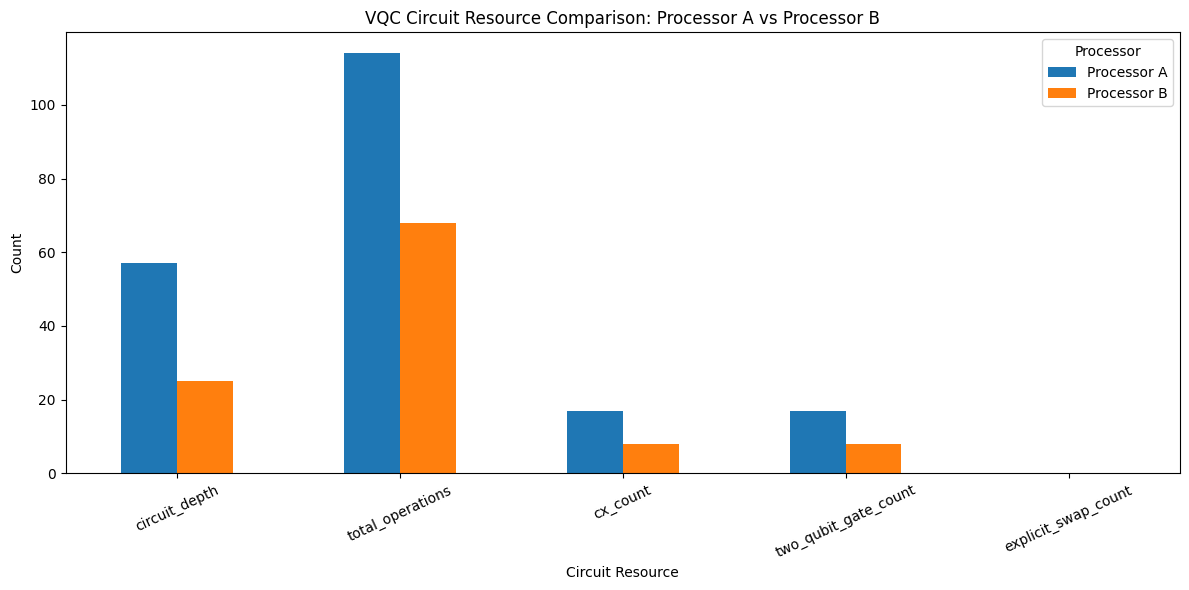

Saved plot: results/processor_AB_metrics.png

STAGE 7 SUMMARY

Processor A:
  Physical qubits available: 5
  Logical qubits used       : 4
  Compiled circuit depth    : 57
  Total operations          : 114
  CX gates                  : 17
  Two-qubit gates           : 17
  Explicit SWAP gates       : 0

Processor B:
  Physical qubits available: 9
  Logical qubits used       : 4
  Compiled circuit depth    : 25
  Total operations          : 68
  CX gates                  : 8
  Two-qubit gates           : 8
  Explicit SWAP gates       : 0

Stage 7 benchmarking completed successfully.
Next: Stage 8 - noisy simulation, if required.


In [49]:

# ============================================================
# STAGE 7: PROCESSOR A vs PROCESSOR B CIRCUIT BENCHMARK
# QFF 2026 - Biomedical Signal Classifier / VQC
# ============================================================

!pip -q install qiskit pandas matplotlib numpy

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit, transpile
from qiskit.transpiler import CouplingMap

# ------------------------------------------------------------
# 1. CREATE REQUIRED DIRECTORIES
# ------------------------------------------------------------

os.makedirs("data/processed", exist_ok=True)
os.makedirs("models", exist_ok=True)
os.makedirs("results", exist_ok=True)

print("Stage 7: Processor A vs Processor B Benchmark")
print("=" * 60)

# ------------------------------------------------------------
# 2. DEFINE PROCESSOR CONFIGURATIONS
# ------------------------------------------------------------

# Use the topology and basis gates specified in the challenge guide.
# Verify these against the latest organizer-provided configuration.

processor_A = {
    "name": "Processor A",
    "num_qubits": 5,
    "coupling_map": [
        [0, 1],
        [1, 2],
        [1, 3],
        [3, 4]
    ],
    "basis_gates": ["rz", "sx", "x", "cx"]
}

processor_B = {
    "name": "Processor B",
    "num_qubits": 9,
    "coupling_map": [
        [0, 1],
        [1, 2],
        [1, 6],
        [2, 3],
        [2, 6],
        [2, 5],
        [3, 4],
        [4, 5],
        [5, 6],
        [6, 7],
        [6, 8],
        [8, 0]
    ],
    "basis_gates": ["rz", "sx", "x", "cx"]
}

# Save processor configurations for reproducibility.
with open("results/processor_configurations.json", "w") as f:
    json.dump(
        {
            "processor_A": processor_A,
            "processor_B": processor_B
        },
        f,
        indent=4
    )

print("Processor configurations loaded successfully.")

# ------------------------------------------------------------
# 3. LOAD QUANTUM-READY DATA
# ------------------------------------------------------------

data_path = "data/processed/quantum_ready_data.npz"

if not os.path.exists(data_path):
    raise FileNotFoundError(
        f"Missing {data_path}. Run Stage 4 first."
    )

data = np.load(data_path)

X_train = np.asarray(data["X_train"], dtype=float)
X_test = np.asarray(data["X_test"], dtype=float)
y_train = np.asarray(data["y_train"], dtype=int)
y_test = np.asarray(data["y_test"], dtype=int)

print("\nDataset loaded:")
print("X_train shape:", X_train.shape)
print("X_test shape :", X_test.shape)
print("Training labels:", np.unique(y_train))
print("Testing labels :", np.unique(y_test))

# ------------------------------------------------------------
# 4. LOAD TRAINED VQC WEIGHTS
# ------------------------------------------------------------

weights_path = "models/vqc_weights.npy"

if not os.path.exists(weights_path):
    raise FileNotFoundError(
        f"Missing {weights_path}. Run Stage 5 first."
    )

weights = np.asarray(np.load(weights_path), dtype=float).flatten()

print("\nNumber of trained parameters:", len(weights))

# ------------------------------------------------------------
# 5. BUILD THE SAME LOGICAL VQC CIRCUIT USED IN STAGE 5
# ------------------------------------------------------------

N_QUBITS = 4
N_LAYERS = 2

expected_parameters = N_LAYERS * N_QUBITS * 2

if len(weights) != expected_parameters:
    raise ValueError(
        f"Expected {expected_parameters} VQC weights "
        f"for {N_LAYERS} layers and {N_QUBITS} qubits, "
        f"but found {len(weights)}. "
        "Check the circuit and weights from Stage 5."
    )

if X_train.shape[1] < N_QUBITS:
    raise ValueError(
        "The dataset must contain at least 4 features."
    )

def build_vqc_circuit(features, trained_weights):
    """
    Reconstruct the Stage 5 VQC architecture:
    - RY angle encoding
    - Trainable RX and RZ rotations
    - CX chain and ring entanglement

    The first four input features are used.
    """
    qc = QuantumCircuit(N_QUBITS)

    features = np.asarray(features, dtype=float).flatten()
    trained_weights = np.asarray(
        trained_weights, dtype=float
    ).flatten()

    if len(features) < N_QUBITS:
        raise ValueError("At least 4 input features are required.")

    if len(trained_weights) != expected_parameters:
        raise ValueError("Unexpected number of trained weights.")

    # Angle encoding
    for q in range(N_QUBITS):
        qc.ry(float(features[q]), q)

    parameter_index = 0

    for layer in range(N_LAYERS):
        # Trainable single-qubit rotations
        for q in range(N_QUBITS):
            qc.rx(float(trained_weights[parameter_index]), q)
            parameter_index += 1

            qc.rz(float(trained_weights[parameter_index]), q)
            parameter_index += 1

        # Entanglement chain
        for q in range(N_QUBITS - 1):
            qc.cx(q, q + 1)

        # Ring entanglement
        qc.cx(N_QUBITS - 1, 0)

    return qc

# Build an unmeasured logical circuit for resource benchmarking.
logical_circuit = build_vqc_circuit(X_train[0], weights)

print("\nLogical VQC circuit created.")
print("Logical qubits:", logical_circuit.num_qubits)
print("Logical circuit depth:", logical_circuit.depth())
print("\nLogical circuit:")
print(logical_circuit.draw(output="text"))

# ------------------------------------------------------------
# 6. BENCHMARK A CIRCUIT ON A PROCESSOR TOPOLOGY
# ------------------------------------------------------------

def benchmark_processor(processor, circuit):
    """
    Compile the logical circuit using the processor's:
    - Coupling map
    - Basis gates

    Then report compiled circuit resources.
    """

    # FIX: CouplingMap accepts couplinglist, not num_qubits.
    # These topologies already contain edges reaching their
    # highest-numbered physical qubits.
    coupling = CouplingMap(
        couplinglist=processor["coupling_map"]
    )

    compiled = transpile(
        circuit,
        basis_gates=processor["basis_gates"],
        coupling_map=coupling,
        optimization_level=1,
        seed_transpiler=42
    )

    # Count operations in the compiled circuit.
    operation_counts = {
        str(gate): int(count)
        for gate, count in compiled.count_ops().items()
    }

    # Count CX operations.
    cx_count = operation_counts.get("cx", 0)

    # Count explicit SWAP gates, if any.
    swap_count = operation_counts.get("swap", 0)

    # Count compiled two-qubit operations.
    two_qubit_names = {
        "cx", "cz", "ecr", "swap",
        "rxx", "ryy", "rzz", "iswap"
    }

    two_qubit_count = sum(
        count
        for gate, count in operation_counts.items()
        if gate.lower() in two_qubit_names
    )

    metrics = {
        "processor": processor["name"],
        "physical_qubits_available": processor["num_qubits"],
        "logical_qubits_used": circuit.num_qubits,
        "circuit_depth": int(compiled.depth()),
        "total_operations": int(compiled.size()),
        "cx_count": int(cx_count),
        "two_qubit_gate_count": int(two_qubit_count),
        "explicit_swap_count": int(swap_count),
        "operations": json.dumps(operation_counts)
    }

    return compiled, metrics

# ------------------------------------------------------------
# 7. BENCHMARK PROCESSOR A AND PROCESSOR B
# ------------------------------------------------------------

compiled_A, metrics_A = benchmark_processor(
    processor_A,
    logical_circuit
)

compiled_B, metrics_B = benchmark_processor(
    processor_B,
    logical_circuit
)

metrics_df = pd.DataFrame([metrics_A, metrics_B])

print("\n" + "=" * 80)
print("PROCESSOR A vs PROCESSOR B: CIRCUIT RESOURCE COMPARISON")
print("=" * 80)

print(
    metrics_df.drop(columns=["operations"]).to_string(
        index=False
    )
)

# ------------------------------------------------------------
# 8. SAVE METRICS AND COMPILED CIRCUITS
# ------------------------------------------------------------

metrics_path = "results/processor_AB_metrics.csv"
metrics_df.to_csv(metrics_path, index=False)

circuits_path = "results/processor_AB_circuits.txt"

with open(circuits_path, "w") as f:
    f.write("LOGICAL VQC CIRCUIT\n")
    f.write("=" * 70 + "\n")
    f.write(str(logical_circuit.draw(output="text")))

    f.write("\n\nCOMPILED CIRCUIT - PROCESSOR A\n")
    f.write("=" * 70 + "\n")
    f.write(str(compiled_A.draw(output="text")))

    f.write("\n\nCOMPILED CIRCUIT - PROCESSOR B\n")
    f.write("=" * 70 + "\n")
    f.write(str(compiled_B.draw(output="text")))

print("\nSaved:")
print("-", metrics_path)
print("-", circuits_path)
print("- results/processor_configurations.json")

# ------------------------------------------------------------
# 9. PLOT RESOURCE COMPARISON
# ------------------------------------------------------------

plot_df = metrics_df.set_index("processor")

plot_columns = [
    "circuit_depth",
    "total_operations",
    "cx_count",
    "two_qubit_gate_count",
    "explicit_swap_count"
]

axes = plot_df[plot_columns].T.plot(
    kind="bar",
    figsize=(12, 6)
)

axes.set_title(
    "VQC Circuit Resource Comparison: Processor A vs Processor B"
)
axes.set_xlabel("Circuit Resource")
axes.set_ylabel("Count")
axes.legend(title="Processor")
axes.tick_params(axis="x", rotation=25)

plt.tight_layout()

plot_path = "results/processor_AB_metrics.png"
plt.savefig(plot_path, dpi=200, bbox_inches="tight")
plt.show()

print("Saved plot:", plot_path)

# ------------------------------------------------------------
# 10. PRINT A SIMPLE INTERPRETATION
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("STAGE 7 SUMMARY")
print("=" * 60)

for _, row in metrics_df.iterrows():
    print(f"\n{row['processor']}:")
    print("  Physical qubits available:", row["physical_qubits_available"])
    print("  Logical qubits used       :", row["logical_qubits_used"])
    print("  Compiled circuit depth    :", row["circuit_depth"])
    print("  Total operations          :", row["total_operations"])
    print("  CX gates                  :", row["cx_count"])
    print("  Two-qubit gates           :", row["two_qubit_gate_count"])
    print("  Explicit SWAP gates       :", row["explicit_swap_count"])

print("\nStage 7 benchmarking completed successfully.")
print("Next: Stage 8 - noisy simulation, if required.")


Test samples available: 455
Test labels: [0 1]
Measurement shots per circuit: 1024

Noise model:
Single-qubit depolarizing probability: 0.001
Two-qubit depolarizing probability: 0.005
Readout error probability: 0.01

Samples selected for noisy simulation: 100
Class distribution: {np.int64(0): np.int64(98), np.int64(1): np.int64(2)}

Running Processor A...
Running Processor B...

NOISY PROCESSOR COMPARISON
  processor  samples_evaluated  shots_per_sample  accuracy  precision  recall  f1_score  mean_circuit_depth  mean_cx_count  mean_two_qubit_gates  mean_explicit_swaps  simulation_time_seconds
Processor A                100              1024      0.98        0.0     0.0       0.0                58.0           17.0                  17.0                  0.0                 8.944318
Processor B                100              1024      0.98        0.0     0.0       0.0                26.0            8.0                   8.0                  0.0                 8.904365

Confusion matrix 

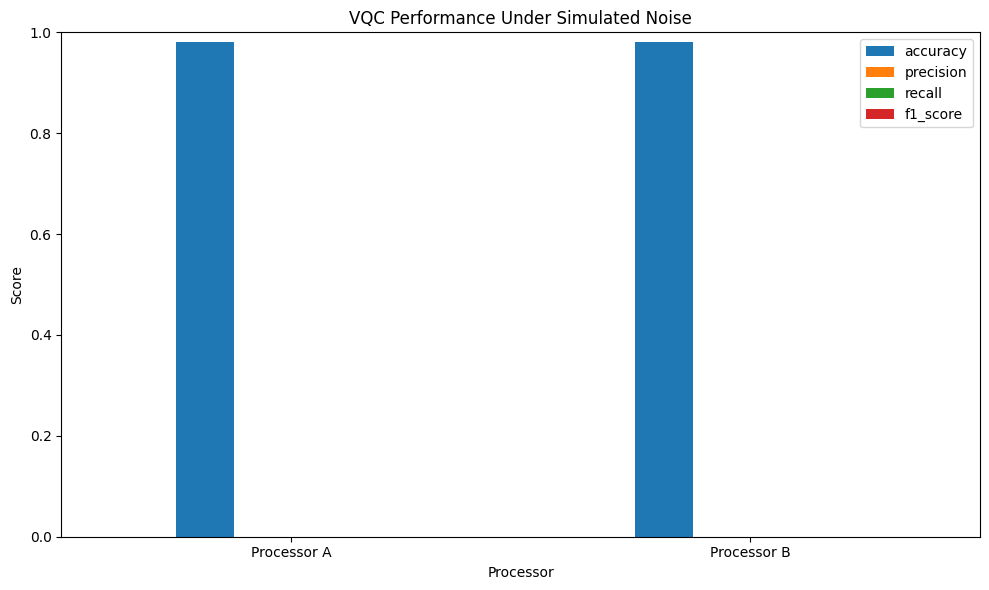


Saved output files:
- results/noisy_processor_comparison.csv
- results/processor_A_noisy_predictions.csv
- results/processor_B_noisy_predictions.csv
- results/noisy_processor_comparison.png

STAGE 8 COMPLETED
Recall is the primary metric for this biomedical task.
Higher recall means fewer abnormal beats are missed.
Compare it alongside precision, F1, and circuit resources.

These results are simulated under the noise assumptions defined in this notebook; they are not measurements from real quantum hardware.


In [51]:

# ============================================================
# STAGE 8: NOISY SIMULATION - PROCESSOR A vs PROCESSOR B
# QFF 2026 Biomedical Signal Classifier / VQC
# ============================================================

!pip -q install qiskit qiskit-aer pandas numpy matplotlib scikit-learn

import os
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit, transpile
from qiskit.transpiler import CouplingMap
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error, ReadoutError

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)
from sklearn.model_selection import train_test_split

# ------------------------------------------------------------
# 1. DIRECTORIES AND INPUT FILES
# ------------------------------------------------------------

os.makedirs("results", exist_ok=True)

DATA_PATH = "data/processed/quantum_ready_data.npz"
WEIGHTS_PATH = "models/vqc_weights.npy"

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError("Run Stage 4 first: processed data is missing.")

if not os.path.exists(WEIGHTS_PATH):
    raise FileNotFoundError("Run Stage 5 first: trained VQC weights are missing.")

data = np.load(DATA_PATH)

X_test = np.asarray(data["X_test"], dtype=float)
y_test = np.asarray(data["y_test"], dtype=int)
weights = np.asarray(np.load(WEIGHTS_PATH), dtype=float).flatten()

N_QUBITS = 4
N_LAYERS = 2
SHOTS = 1024
MAX_TEST_SAMPLES = 100

if X_test.shape[1] < N_QUBITS:
    raise ValueError("Stage 8 requires at least four input features.")

expected_weights = N_LAYERS * N_QUBITS * 2

if len(weights) != expected_weights:
    raise ValueError(
        f"Expected {expected_weights} weights but found {len(weights)}. "
        "Match the circuit architecture to Stage 5."
    )

print("Test samples available:", len(y_test))
print("Test labels:", np.unique(y_test))
print("Measurement shots per circuit:", SHOTS)

# ------------------------------------------------------------
# 2. PROCESSOR CONFIGURATIONS
# ------------------------------------------------------------

processor_A = {
    "name": "Processor A",
    "num_qubits": 5,
    "coupling_map": [
        [0, 1], [1, 2], [1, 3], [3, 4]
    ],
    "basis_gates": ["rz", "sx", "x", "cx"]
}

processor_B = {
    "name": "Processor B",
    "num_qubits": 9,
    "coupling_map": [
        [0, 1], [1, 2], [1, 6], [2, 3],
        [2, 6], [2, 5], [3, 4], [4, 5],
        [5, 6], [6, 7], [6, 8], [8, 0]
    ],
    "basis_gates": ["rz", "sx", "x", "cx"]
}

# ------------------------------------------------------------
# 3. RECONSTRUCT THE STAGE 5 VQC CIRCUIT
# ------------------------------------------------------------

def build_vqc(features, trained_weights):
    qc = QuantumCircuit(N_QUBITS)

    features = np.asarray(features, dtype=float).flatten()
    trained_weights = np.asarray(trained_weights, dtype=float).flatten()

    # Angle encoding
    for q in range(N_QUBITS):
        qc.ry(float(features[q]), q)

    index = 0

    for _ in range(N_LAYERS):
        for q in range(N_QUBITS):
            qc.rx(float(trained_weights[index]), q)
            index += 1

            qc.rz(float(trained_weights[index]), q)
            index += 1

        # Entanglement chain
        for q in range(N_QUBITS - 1):
            qc.cx(q, q + 1)

        # Ring connection
        qc.cx(N_QUBITS - 1, 0)

    return qc

# ------------------------------------------------------------
# 4. DEFINE A NOISE MODEL
# ------------------------------------------------------------

# Starter assumptions ONLY.
# Replace these with the official challenge noise parameters
# before reporting results as processor-specific estimates.

P_1Q = 0.001
P_2Q = 0.005
READOUT_ERROR = 0.01

noise_model = NoiseModel()

# RZ is treated as virtual and noiseless in this starter model.
# Apply single-qubit depolarizing noise to SX and X.
single_qubit_error = depolarizing_error(P_1Q, 1)
two_qubit_error = depolarizing_error(P_2Q, 2)

noise_model.add_all_qubit_quantum_error(
    single_qubit_error, ["sx", "x"]
)
noise_model.add_all_qubit_quantum_error(
    two_qubit_error, ["cx"]
)

readout_error = ReadoutError([
    [1 - READOUT_ERROR, READOUT_ERROR],
    [READOUT_ERROR, 1 - READOUT_ERROR]
])

noise_model.add_all_qubit_readout_error(readout_error)

print("\nNoise model:")
print("Single-qubit depolarizing probability:", P_1Q)
print("Two-qubit depolarizing probability:", P_2Q)
print("Readout error probability:", READOUT_ERROR)

# ------------------------------------------------------------
# 5. PREPARE A REPRODUCIBLE TEST SUBSET
# ------------------------------------------------------------

sample_count = min(MAX_TEST_SAMPLES, len(y_test))
all_indices = np.arange(len(y_test))

if sample_count < len(y_test):
    selected_indices, _ = train_test_split(
        all_indices,
        train_size=sample_count,
        random_state=42,
        stratify=y_test
    )
else:
    selected_indices = all_indices

X_eval = X_test[selected_indices]
y_eval = y_test[selected_indices]

print("\nSamples selected for noisy simulation:", len(y_eval))
print("Class distribution:", dict(zip(*np.unique(y_eval, return_counts=True))))

# ------------------------------------------------------------
# 6. RUN NOISY SIMULATION FOR EACH PROCESSOR
# ------------------------------------------------------------

def run_processor(processor, X_eval, y_eval):
    coupling = CouplingMap(
        couplinglist=processor["coupling_map"]
    )

    simulator = AerSimulator(noise_model=noise_model)

    y_pred = []
    y_prob = []

    depths = []
    cx_counts = []
    two_qubit_counts = []
    swap_counts = []

    start_time = time.time()

    for features in X_eval:
        # Build logical circuit and add measurement.
        qc = build_vqc(features, weights)
        qc.measure_all()

        # Compile onto the processor topology.
        compiled = transpile(
            qc,
            basis_gates=processor["basis_gates"],
            coupling_map=coupling,
            optimization_level=1,
            seed_transpiler=42
        )

        depths.append(int(compiled.depth()))

        ops = {
            str(gate): int(count)
            for gate, count in compiled.count_ops().items()
        }

        cx_counts.append(ops.get("cx", 0))
        swap_counts.append(ops.get("swap", 0))

        two_qubit_names = {
            "cx", "cz", "ecr", "swap",
            "rxx", "ryy", "rzz", "iswap"
        }

        two_qubit_counts.append(
            sum(
                count for gate, count in ops.items()
                if gate.lower() in two_qubit_names
            )
        )

        job = simulator.run(
            compiled,
            shots=SHOTS,
            seed_simulator=42
        )

        counts = job.result().get_counts()

        # measure_all maps qubit 0 to classical bit 0.
        # Qiskit displays classical bit 0 at the rightmost end.
        total_shots = sum(counts.values())
        class_1_shots = sum(
            count for bitstring, count in counts.items()
            if bitstring.replace(" ", "")[-1] == "1"
        )

        probability_class_1 = class_1_shots / total_shots
        prediction = int(probability_class_1 >= 0.5)

        y_prob.append(probability_class_1)
        y_pred.append(prediction)

    elapsed = time.time() - start_time

    metrics = {
        "processor": processor["name"],
        "samples_evaluated": len(y_eval),
        "shots_per_sample": SHOTS,
        "accuracy": accuracy_score(y_eval, y_pred),
        "precision": precision_score(
            y_eval, y_pred, zero_division=0
        ),
        "recall": recall_score(
            y_eval, y_pred, zero_division=0
        ),
        "f1_score": f1_score(
            y_eval, y_pred, zero_division=0
        ),
        "mean_circuit_depth": float(np.mean(depths)),
        "mean_cx_count": float(np.mean(cx_counts)),
        "mean_two_qubit_gates": float(np.mean(two_qubit_counts)),
        "mean_explicit_swaps": float(np.mean(swap_counts)),
        "simulation_time_seconds": elapsed
    }

    predictions = pd.DataFrame({
        "test_index": selected_indices,
        "actual_label": y_eval,
        "predicted_label": y_pred,
        "probability_class_1": y_prob
    })

    return metrics, predictions

print("\nRunning Processor A...")
metrics_A, predictions_A = run_processor(
    processor_A, X_eval, y_eval
)

print("Running Processor B...")
metrics_B, predictions_B = run_processor(
    processor_B, X_eval, y_eval
)

# ------------------------------------------------------------
# 7. SAVE METRICS AND PREDICTIONS
# ------------------------------------------------------------

comparison = pd.DataFrame([metrics_A, metrics_B])

comparison_path = "results/noisy_processor_comparison.csv"
comparison.to_csv(comparison_path, index=False)

predictions_A.to_csv(
    "results/processor_A_noisy_predictions.csv",
    index=False
)

predictions_B.to_csv(
    "results/processor_B_noisy_predictions.csv",
    index=False
)

print("\nNOISY PROCESSOR COMPARISON")
print("=" * 80)
print(comparison.to_string(index=False))

print("\nConfusion matrix - Processor A:")
print(confusion_matrix(
    predictions_A["actual_label"],
    predictions_A["predicted_label"],
    labels=[0, 1]
))

print("\nConfusion matrix - Processor B:")
print(confusion_matrix(
    predictions_B["actual_label"],
    predictions_B["predicted_label"],
    labels=[0, 1]
))

# ------------------------------------------------------------
# 8. PLOT METRIC COMPARISON
# ------------------------------------------------------------

metric_columns = ["accuracy", "precision", "recall", "f1_score"]

ax = comparison.set_index("processor")[metric_columns].plot(
    kind="bar",
    figsize=(10, 6),
    ylim=(0, 1)
)

ax.set_title("VQC Performance Under Simulated Noise")
ax.set_ylabel("Score")
ax.set_xlabel("Processor")
ax.tick_params(axis="x", rotation=0)

plt.tight_layout()

plot_path = "results/noisy_processor_comparison.png"
plt.savefig(plot_path, dpi=200, bbox_inches="tight")
plt.show()

print("\nSaved output files:")
print("-", comparison_path)
print("- results/processor_A_noisy_predictions.csv")
print("- results/processor_B_noisy_predictions.csv")
print("-", plot_path)

# ------------------------------------------------------------
# 9. INTERPRET RESULTS
# ------------------------------------------------------------

print("\nSTAGE 8 COMPLETED")
print("=" * 60)
print("Recall is the primary metric for this biomedical task.")
print("Higher recall means fewer abnormal beats are missed.")
print("Compare it alongside precision, F1, and circuit resources.")
print(
    "\nThese results are simulated under the noise assumptions "
    "defined in this notebook; they are not measurements from "
    "real quantum hardware."
)


STAGE 9: FINAL EVALUATION

Checking previous stage outputs:
logistic_regression       : NOT FOUND
model_comparison          : FOUND
processor_AB              : FOUND
noisy_processors          : FOUND
vqc                       : FOUND

Existing model comparison:
              Model  Accuracy  Precision   Recall  F1-score
Logistic Regression  0.718681   0.023622 0.428571  0.044776
                VQC  0.984615   0.000000 0.000000  0.000000

Processor resource comparison:
  processor  physical_qubits_available  logical_qubits_used  circuit_depth  total_operations  cx_count  two_qubit_gate_count  explicit_swap_count                     operations
Processor A                          5                    4             57               114        17                    17                    0 {"rz": 63, "sx": 34, "cx": 17}
Processor B                          9                    4             25                68         8                     8                    0  {"rz": 38, "sx": 22, "cx"

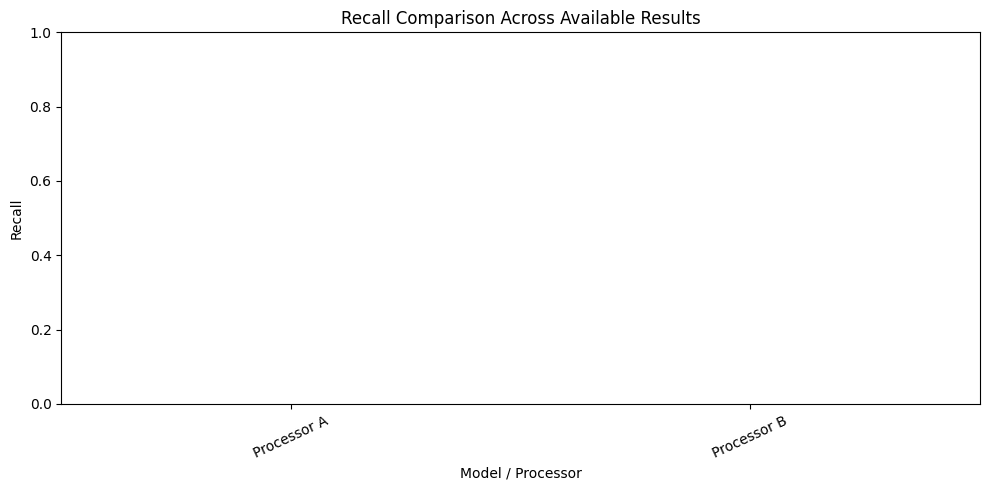


Saved: results/final_project_summary.txt

STAGE 9 COMPLETED
Review the CSV files before using any values in your submission.


In [52]:

# ==========`==================================================
# STAGE 9: FINAL EVALUATION AND SUBMISSION RESULTS
# QFF 2026 - Biomedical Signal Classifier / VQC
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

os.makedirs("results", exist_ok=True)

print("=" * 70)
print("STAGE 9: FINAL EVALUATION")
print("=" * 70)

# ------------------------------------------------------------
# 1. LOAD AVAILABLE RESULTS
# ------------------------------------------------------------

result_files = {
    "logistic_regression": "results/logistic_regression_metrics.csv",
    "model_comparison": "results/model_comparison.csv",
    "processor_AB": "results/processor_AB_metrics.csv",
    "noisy_processors": "results/noisy_processor_comparison.csv",
    "vqc": "results/vqc_metrics.csv"
}

print("\nChecking previous stage outputs:")

for name, path in result_files.items():
    print(f"{name:25} : {'FOUND' if os.path.exists(path) else 'NOT FOUND'}")

# ------------------------------------------------------------
# 2. LOAD MODEL COMPARISON RESULTS
# ------------------------------------------------------------

comparison_path = "results/model_comparison.csv"

if os.path.exists(comparison_path):
    model_comparison = pd.read_csv(comparison_path)

    print("\nExisting model comparison:")
    print(model_comparison.to_string(index=False))

else:
    model_comparison = None
    print(
        "\nNo model_comparison.csv found. "
        "Run Stage 6 and check its output path."
    )

# ------------------------------------------------------------
# 3. LOAD PROCESSOR RESOURCE METRICS
# ------------------------------------------------------------

processor_path = "results/processor_AB_metrics.csv"

if os.path.exists(processor_path):
    processor_metrics = pd.read_csv(processor_path)

    print("\nProcessor resource comparison:")
    print(processor_metrics.to_string(index=False))

else:
    processor_metrics = None
    print("Processor resource metrics unavailable. Run Stage 7.")

# ------------------------------------------------------------
# 4. LOAD NOISY SIMULATION RESULTS
# ------------------------------------------------------------

noisy_path = "results/noisy_processor_comparison.csv"

if os.path.exists(noisy_path):
    noisy_metrics = pd.read_csv(noisy_path)

    print("\nNoisy simulation comparison:")
    print(noisy_metrics.to_string(index=False))

else:
    noisy_metrics = None
    print("Noisy simulation results unavailable. Run Stage 8.")

# ------------------------------------------------------------
# 5. CREATE A CONSOLIDATED RESULTS TABLE
# ------------------------------------------------------------

rows = []

# Include the classical baseline and VQC results when available.
if model_comparison is not None:
    for _, row in model_comparison.iterrows():
        rows.append({
            "section": "Classical vs VQC",
            "model_or_processor": str(
                row.get("model", row.get("Model", "Unknown"))
            ),
            "accuracy": row.get("accuracy", np.nan),
            "precision": row.get("precision", np.nan),
            "recall": row.get("recall", np.nan),
            "f1_score": row.get(
                "f1_score", row.get("f1", np.nan)
            ),
            "circuit_depth": np.nan,
            "cx_count": np.nan,
            "two_qubit_gates": np.nan
        })

# Include processor-specific noisy results.
if noisy_metrics is not None:
    for _, row in noisy_metrics.iterrows():
        rows.append({
            "section": "Noisy VQC simulation",
            "model_or_processor": row.get("processor", "Unknown"),
            "accuracy": row.get("accuracy", np.nan),
            "precision": row.get("precision", np.nan),
            "recall": row.get("recall", np.nan),
            "f1_score": row.get("f1_score", np.nan),
            "circuit_depth": row.get("mean_circuit_depth", np.nan),
            "cx_count": row.get("mean_cx_count", np.nan),
            "two_qubit_gates": row.get(
                "mean_two_qubit_gates", np.nan
            )
        })

final_results = pd.DataFrame(rows)

final_path = "results/final_consolidated_results.csv"
final_results.to_csv(final_path, index=False)

print("\nConsolidated results:")
if not final_results.empty:
    print(final_results.to_string(index=False))
else:
    print("No compatible metrics found. Check previous stage outputs.")

print("\nSaved:", final_path)

# ------------------------------------------------------------
# 6. PLOT RECALL COMPARISON
# ------------------------------------------------------------

if not final_results.empty:
    recall_data = final_results.dropna(subset=["recall"])

    if not recall_data.empty:
        recall_plot = recall_data[
            ["model_or_processor", "recall"]
        ].copy()

        ax = recall_plot.set_index(
            "model_or_processor"
        ).plot(
            kind="bar",
            figsize=(10, 5),
            ylim=(0, 1),
            legend=False
        )

        ax.set_title("Recall Comparison Across Available Results")
        ax.set_ylabel("Recall")
        ax.set_xlabel("Model / Processor")
        ax.tick_params(axis="x", rotation=25)

        plt.tight_layout()
        plt.savefig(
            "results/final_recall_comparison.png",
            dpi=200,
            bbox_inches="tight"
        )
        plt.show()

# ------------------------------------------------------------
# 7. EXPORT A SUMMARY REPORT
# ------------------------------------------------------------

report_path = "results/final_project_summary.txt"

with open(report_path, "w") as f:
    f.write("QFF 2026 - Biomedical Signal Classifier / VQC\n")
    f.write("=" * 65 + "\n\n")

    f.write("PROJECT PIPELINE\n")
    f.write("1. Load ECG data and annotations\n")
    f.write("2. Filter ECG signal and segment heartbeat windows\n")
    f.write("3. Extract features and prepare quantum-ready data\n")
    f.write("4. Train the Variational Quantum Classifier\n")
    f.write("5. Train and evaluate Logistic Regression baseline\n")
    f.write("6. Compare circuit resources on Processor A and B\n")
    f.write("7. Simulate the VQC under an assumed noise model\n\n")

    f.write("IMPORTANT LIMITATIONS\n")
    f.write(
        "- Clearly document the normal/abnormal label mapping.\n"
    )
    f.write(
        "- A beat-level random split from one ECG record does not "
        "establish generalization to unseen patients.\n"
    )
    f.write(
        "- Report the exact dataset, split, features, threshold, "
        "optimizer, shots, and noise parameters.\n"
    )
    f.write(
        "- Noisy simulator results are not real hardware measurements.\n"
    )
    f.write(
        "- Do not claim quantum advantage from these comparisons alone.\n"
    )
    f.write(
        "- Use official processor noise/configuration data when required.\n"
    )

    f.write("\nGENERATED OUTPUTS\n")
    f.write("- final_consolidated_results.csv\n")
    f.write("- final_recall_comparison.png (if metrics are available)\n")
    f.write("- processor_AB_metrics.csv (if Stage 7 completed)\n")
    f.write("- noisy_processor_comparison.csv (if Stage 8 completed)\n")

print("\nSaved:", report_path)

print("\n" + "=" * 70)
print("STAGE 9 COMPLETED")
print("=" * 70)
print("Review the CSV files before using any values in your submission.")


In [53]:

# ============================================================
# STAGE 10: QFF REPOSITORY SETUP
# ============================================================

import os
import json
from pathlib import Path

ROOT = Path("QFF-Biomedical-Signal-Classifier")

folders = [
    "data/raw",
    "data/processed",
    "processors",
    "src",
    "results/tables",
    "results/figures",
    "assets",
]

for folder in folders:
    (ROOT / folder).mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# PROCESSOR CONFIGURATIONS
# ------------------------------------------------------------

processor_A = {
    "name": "Processor A",
    "num_qubits": 5,
    "coupling_map": [[0, 1], [1, 2], [1, 3], [3, 4]],
    "basis_gates": ["rz", "sx", "x", "cx"]
}

processor_B = {
    "name": "Processor B",
    "num_qubits": 9,
    "coupling_map": [
        [0, 1], [1, 2], [1, 6], [2, 3],
        [2, 6], [2, 5], [3, 4], [4, 5],
        [5, 6], [6, 7], [6, 8], [8, 0]
    ],
    "basis_gates": ["rz", "sx", "x", "cx"]
}

for filename, config in [
    ("processor_A.json", processor_A),
    ("processor_B.json", processor_B)
]:
    path = ROOT / "processors" / filename
    if not path.exists():
        path.write_text(json.dumps(config, indent=4))

# ------------------------------------------------------------
# SOURCE FILE INITIALIZERS
# ------------------------------------------------------------

source_files = {
    "src/__init__.py": "",
    "src/problem.py": '''"""
Biomedical Signal Classifier.
Document the ECG preprocessing, label mapping,
feature extraction, and VQC implementation here.
"""
''',
    "src/processors.py": '''"""
Processor A/B topology definitions and noise models.
Use the official challenge configuration for final results.
"""
''',
    "src/routing.py": '''"""
Circuit transpilation and routing utilities.
"""
''',
    "src/metrics.py": '''"""
Classification and circuit resource metrics.
Include accuracy, precision, recall, F1, depth,
CX count, and SWAP/routing overhead.
"""
''',
    "src/visualization.py": '''"""
Plot processor coupling graphs and comparison figures.
"""
'''
}

for filename, content in source_files.items():
    path = ROOT / filename
    if not path.exists():
        path.write_text(content)

# ------------------------------------------------------------
# REQUIREMENTS
# ------------------------------------------------------------

requirements = """\
qiskit
qiskit-aer
numpy
pandas
scipy
scikit-learn
matplotlib
networkx
wfdb
joblib
"""

path = ROOT / "requirements.txt"
if not path.exists():
    path.write_text(requirements)

# ------------------------------------------------------------
# README
# ------------------------------------------------------------

readme = """\
# QFF 2026 — Biomedical Signal Classifier

## Problem Statement
**PS-Q1: Biomedical Signal Classifier**

Build a hybrid quantum-classical Variational Quantum Classifier (VQC)
to classify short ECG segments as normal or abnormal and compare its
performance with Logistic Regression.

## Objectives
- Preprocess ECG data and extract numeric features.
- Encode features into a parameterized quantum circuit.
- Train and evaluate a VQC.
- Compare the VQC with Logistic Regression on the same split.
- Benchmark the same logical circuit on Processor A and Processor B.
- Analyze circuit depth, CX gates, routing overhead, and simulated noise.

## Dataset and Labels
Dataset: MIT-BIH Arrhythmia Database, Record 100.

Document the exact annotation symbols used, the normal/abnormal
label mapping, the sampling rate, segmentation window, extracted
features, and the number of samples in each class.

The binary labels are a simplified experimental grouping and
should not be interpreted as a clinical diagnosis.

## Methodology
1. Load ECG signal and annotations.
2. Filter the signal and segment heartbeat windows.
3. Extract and scale features using training data only.
4. Train the VQC with a classical optimizer.
5. Train Logistic Regression using the same features and split.
6. Transpile the circuit onto Processor A and Processor B.
7. Evaluate classification metrics and circuit resources.
8. Run noisy simulation using documented noise assumptions.

## Results
Add measured results from your generated CSV files:
- Accuracy, precision, recall, and F1.
- Processor A/B circuit depth and CX counts.
- SWAP/routing overhead and noisy simulation results.

Do not invent or estimate missing results.

## Reproducibility
- Main experiment notebook: `main.ipynb`
- Dependencies: `requirements.txt`
- Processor configurations: `processors/`
- Source utilities: `src/`
- Tables and plots: `results/`

Run the notebook from top to bottom in the documented environment.

## Limitations
A random beat-level split from one record does not establish
generalization to unseen patients. The label grouping is simplified.
Simulated results are not real hardware measurements, and this
experiment does not establish quantum advantage.

## Team
Add team members and institutional details here.
"""

path = ROOT / "README.md"
if not path.exists():
    path.write_text(readme)

# ------------------------------------------------------------
# REPORT TEMPLATE
# ------------------------------------------------------------

report = """\
# PS-Q1 Experimental Report

## 1. Problem and Motivation
Describe the ECG classification task and why recall matters.

## 2. Dataset and Preprocessing
Document the dataset, record IDs, annotation symbols, label mapping,
segmentation window, filtering, extracted features, and class counts.

## 3. Experimental Protocol
Document the fixed train/test split, random seeds, scaling, threshold,
optimizer, number of training iterations, and simulation shots.

## 4. Classical Baseline
Report Logistic Regression results using the same features and split.

## 5. VQC Architecture and Training
Describe angle encoding, qubit count, layers, trainable gates,
entanglement, loss function, and optimizer.

## 6. Processor A vs Processor B
Include coupling diagrams and a measured table of circuit depth,
CX count, SWAP/routing overhead, and classification metrics.

## 7. Noise Analysis
State the exact noise assumptions and compare ideal/noisy results.
Clearly distinguish simulation from hardware execution.

## 8. Results and Interpretation
Insert actual values from exported CSV files. Explain observed
differences using evidence from your benchmark.

## 9. Limitations
Discuss sample size, class imbalance, label mapping, single-record
evaluation, noise-model assumptions, and reproducibility.

## 10. Conclusion
Summarize findings without claiming quantum advantage unless
supported by rigorous evidence.
"""

path = ROOT / "report.md"
if not path.exists():
    path.write_text(report)

# ------------------------------------------------------------
# GITIGNORE
# ------------------------------------------------------------

gitignore = """\
__pycache__/
*.py[cod]
.ipynb_checkpoints/
.env
.venv/
venv/
.DS_Store

# Do not commit large or restricted raw datasets.
# Keep small, permitted processed artifacts if required for reproduction.
data/raw/*
!data/raw/README.md
"""

path = ROOT / ".gitignore"
if not path.exists():
    path.write_text(gitignore)

print("Stage 10 repository structure created:")
print(ROOT.resolve())

for path in sorted(ROOT.rglob("*")):
    if path.is_file():
        print(" -", path.relative_to(ROOT))

print("\\nNext: copy your completed notebook into this folder as main.ipynb.")


Stage 10 repository structure created:
/content/QFF-Biomedical-Signal-Classifier
 - .gitignore
 - README.md
 - processors/processor_A.json
 - processors/processor_B.json
 - report.md
 - requirements.txt
 - src/__init__.py
 - src/metrics.py
 - src/problem.py
 - src/processors.py
 - src/routing.py
 - src/visualization.py
\nNext: copy your completed notebook into this folder as main.ipynb.


In [54]:

import os

for folder in ["results", "models"]:
    print(f"\n--- {folder}/ ---")

    if os.path.exists(folder):
        for filename in sorted(os.listdir(folder)):
            print(filename)
    else:
        print("Folder not found")



--- results/ ---
figures
final_consolidated_results.csv
final_project_summary.txt
final_recall_comparison.png
model_comparison.csv
noisy_processor_comparison.csv
noisy_processor_comparison.png
processor_AB_circuits.txt
processor_AB_metrics.csv
processor_AB_metrics.png
processor_A_noisy_predictions.csv
processor_B_noisy_predictions.csv
processor_configurations.json
tables
vqc_metrics.csv
vqc_test_predictions.csv

--- models/ ---
vqc_weights.npy


In [55]:

from google.colab import files
import os

files_to_download = [
    "results/processor_AB_metrics.csv",
    "results/noisy_processor_comparison.csv",
    "results/model_comparison.csv",
    "results/final_consolidated_results.csv",
    "results/processor_AB_metrics.png",
    "results/noisy_processor_comparison.png",
    "results/final_recall_comparison.png",
]

for path in files_to_download:
    if os.path.exists(path):
        print("Downloading:", path)
        files.download(path)
    else:
        print("Skipping missing file:", path)


Downloading: results/processor_AB_metrics.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloading: results/noisy_processor_comparison.csv


<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloading: results/final_recall_comparison.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>